# Задание 4. PCA, t-SNE, UMAP и PaCMAP

Исследуем три двоичные матрицы, облака точек около ячеек матрицы 256×256
и Dry Bean Dataset. В корреляционном PCA каждый признак центрируется и делится
на выборочное стандартное отклонение.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="ticks")
SEED = 42

In [2]:
def inspect_data(raw, features, target="class"):
    df = raw.dropna(subset=[*features, target]).copy()
    display(pd.DataFrame({
        "исходные строки": [len(raw)],
        "исходные столбцы": [raw.shape[1]],
        "исходные признаки": [raw.shape[1] - 1],
        "выбранные признаки": [len(features)],
        "классы": [raw[target].nunique()],
        "строки с пропусками, %": [100 * raw.isna().any(axis=1).mean()],
        "строки после очистки": [len(df)],
    }))
    display(pd.concat(
        [raw[target].value_counts().rename("до"), df[target].value_counts().rename("после")],
        axis=1,
    ).sort_index())
    display(df[features].describe().round(3))
    for label, subset in [("Вся выборка", df), *df.groupby(target, sort=True)]:
        display(subset[features].corr(method="pearson").round(3)
                .style.set_caption(f"Корреляция Пирсона · {label}"))
    return df

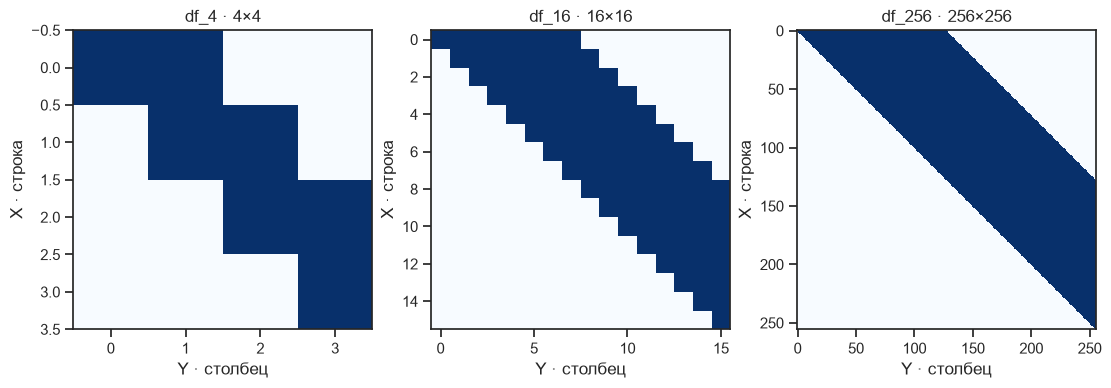

In [3]:
import os
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

import pacmap
import umap

def band_matrix(size):
    i, j = np.indices((size, size))
    return ((0 <= j - i) & (j - i < size // 2)).astype(np.int8)

matrices = {n: band_matrix(n) for n in (4, 16, 256)}
fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")
for n, ax in zip(matrices, axes):
    matrix = matrices[n]
    assert matrix.shape == (n, n)
    assert matrix.sum(axis=1).tolist() == [min(n // 2, n - i) for i in range(n)]
    ax.imshow(matrix, cmap="Blues", interpolation="nearest", vmin=0, vmax=1)
    ax.set(xlabel="Y · столбец", ylabel="X · строка", title=f"df_{n} · {n}×{n}")
plt.show()

## Корреляционный PCA матриц

Для каждой матрицы показываем scree plot и все пары PC1–PC4. У df_4 после
центрирования ранг не превышает трёх, поэтому PC4 имеет нулевую дисперсию.
PC129–PC133 существуют только у df_256. На biplot стрелки показывают корреляции
исходных признаков с компонентами, умноженные на общий для панели коэффициент
для удобства чтения. При 256 стрелках подписываем шесть самых длинных.

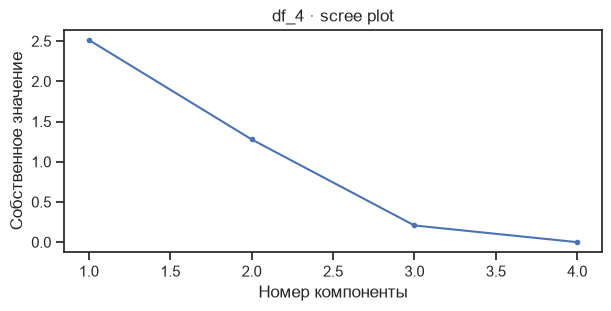

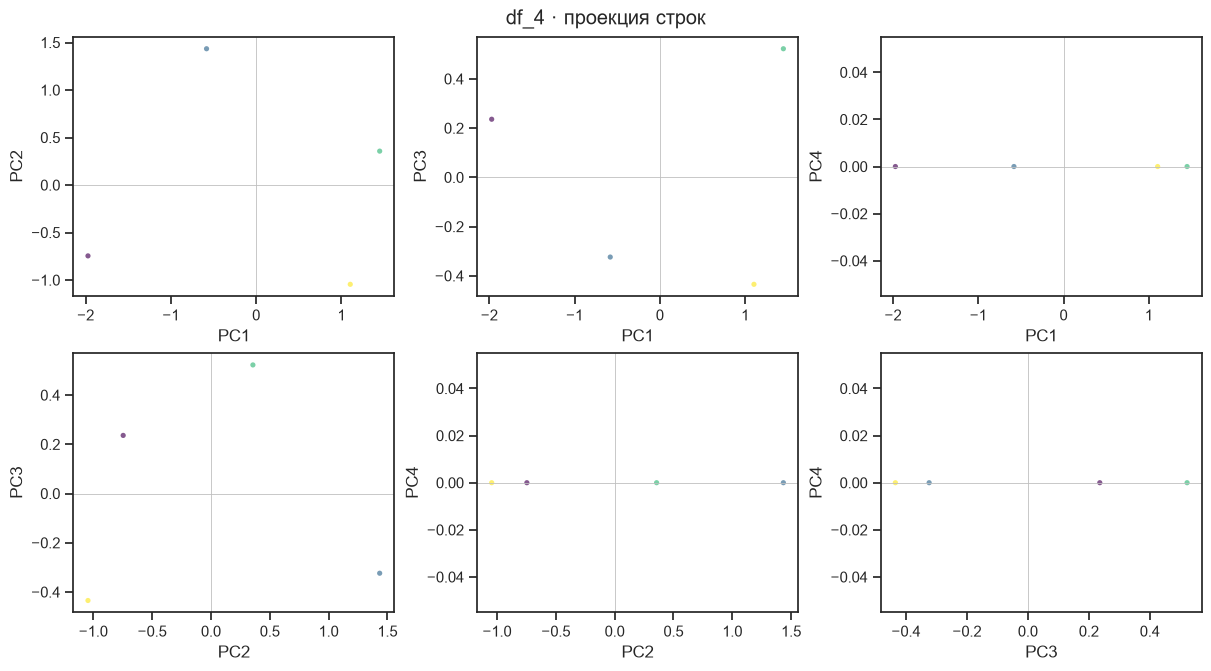

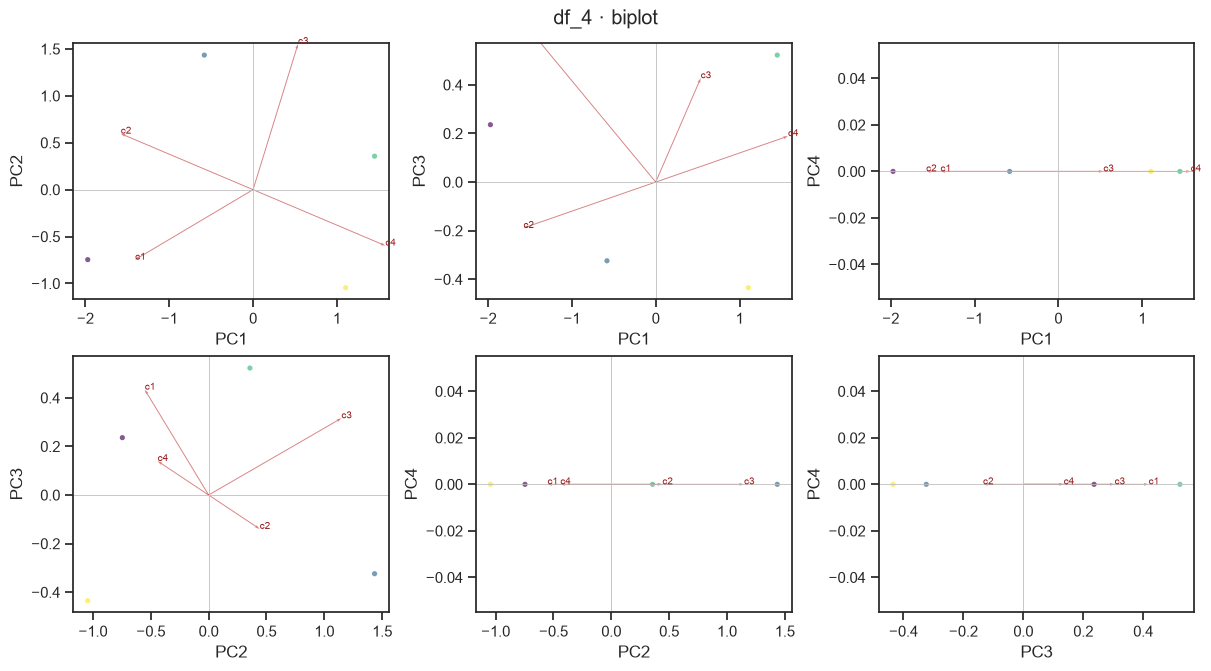

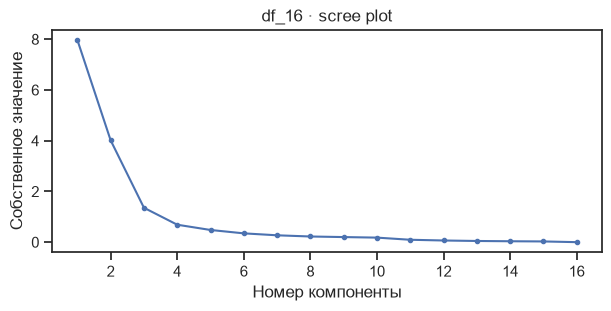

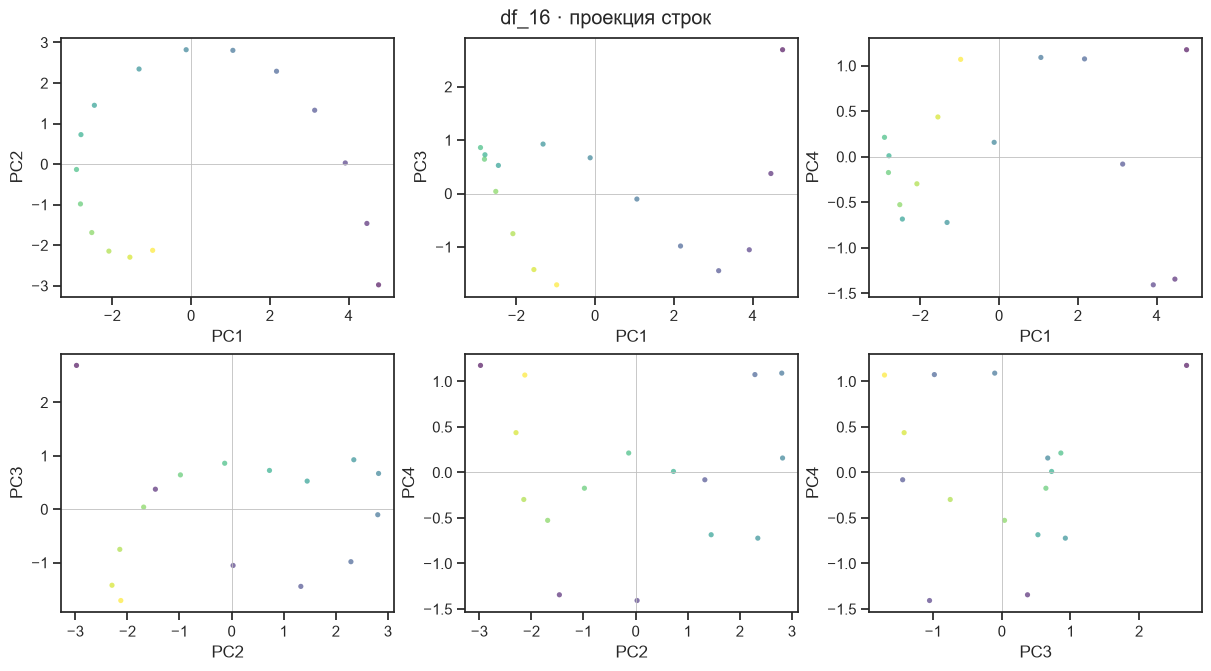

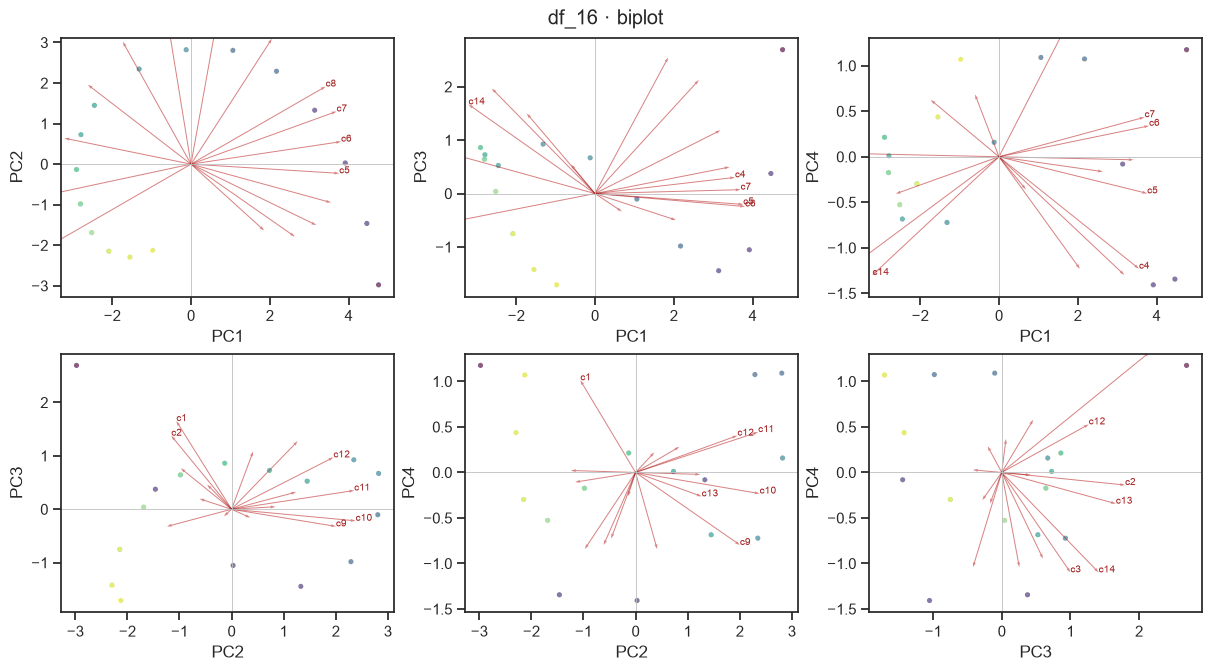

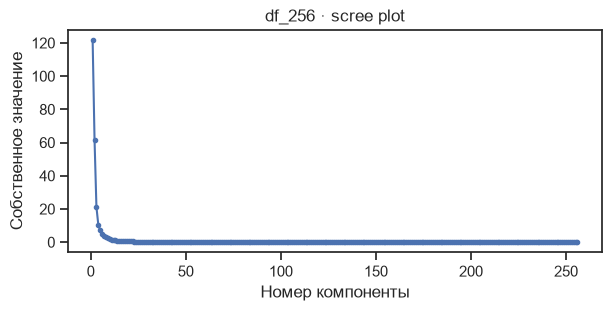

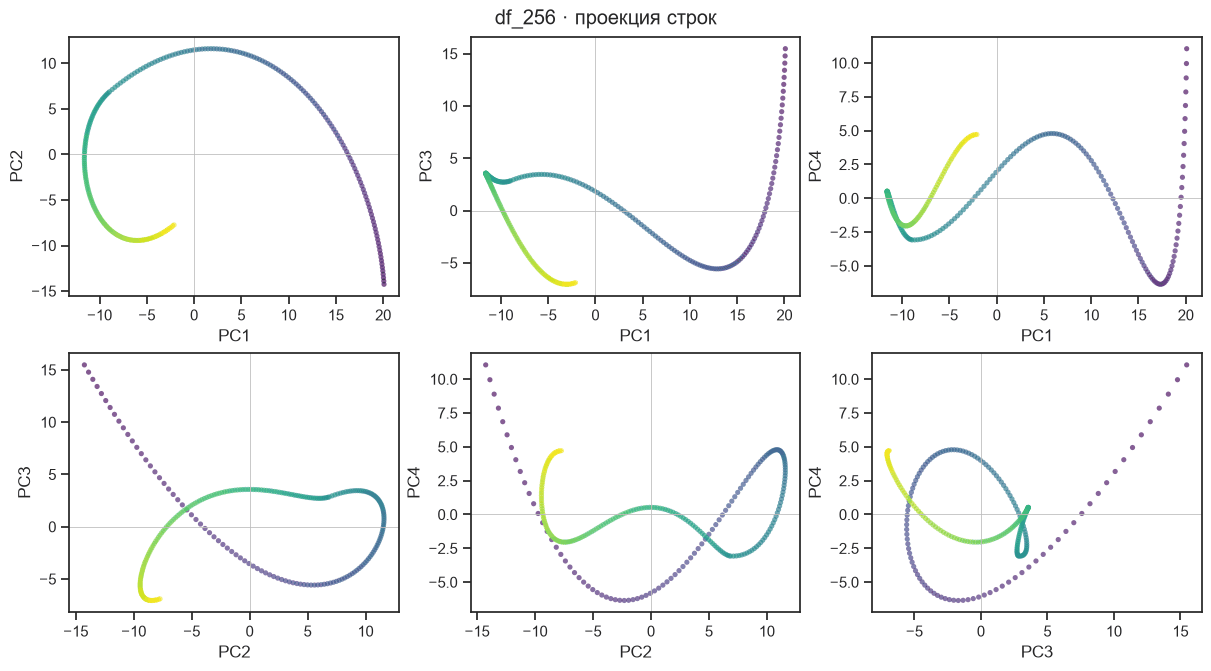

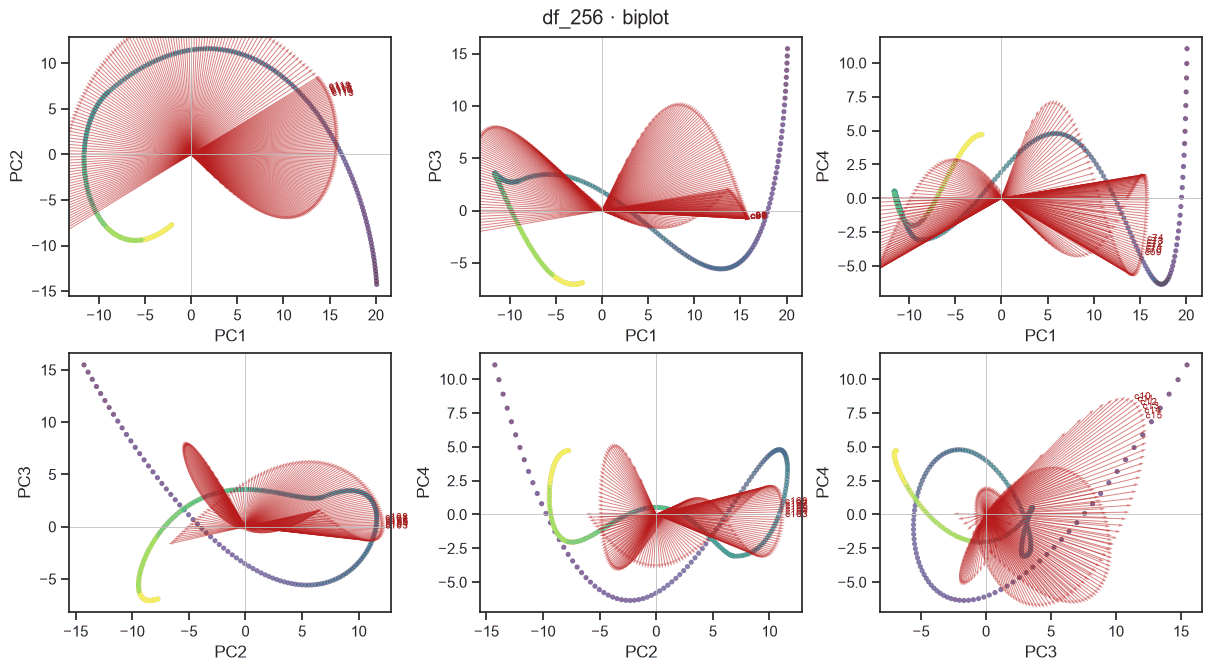

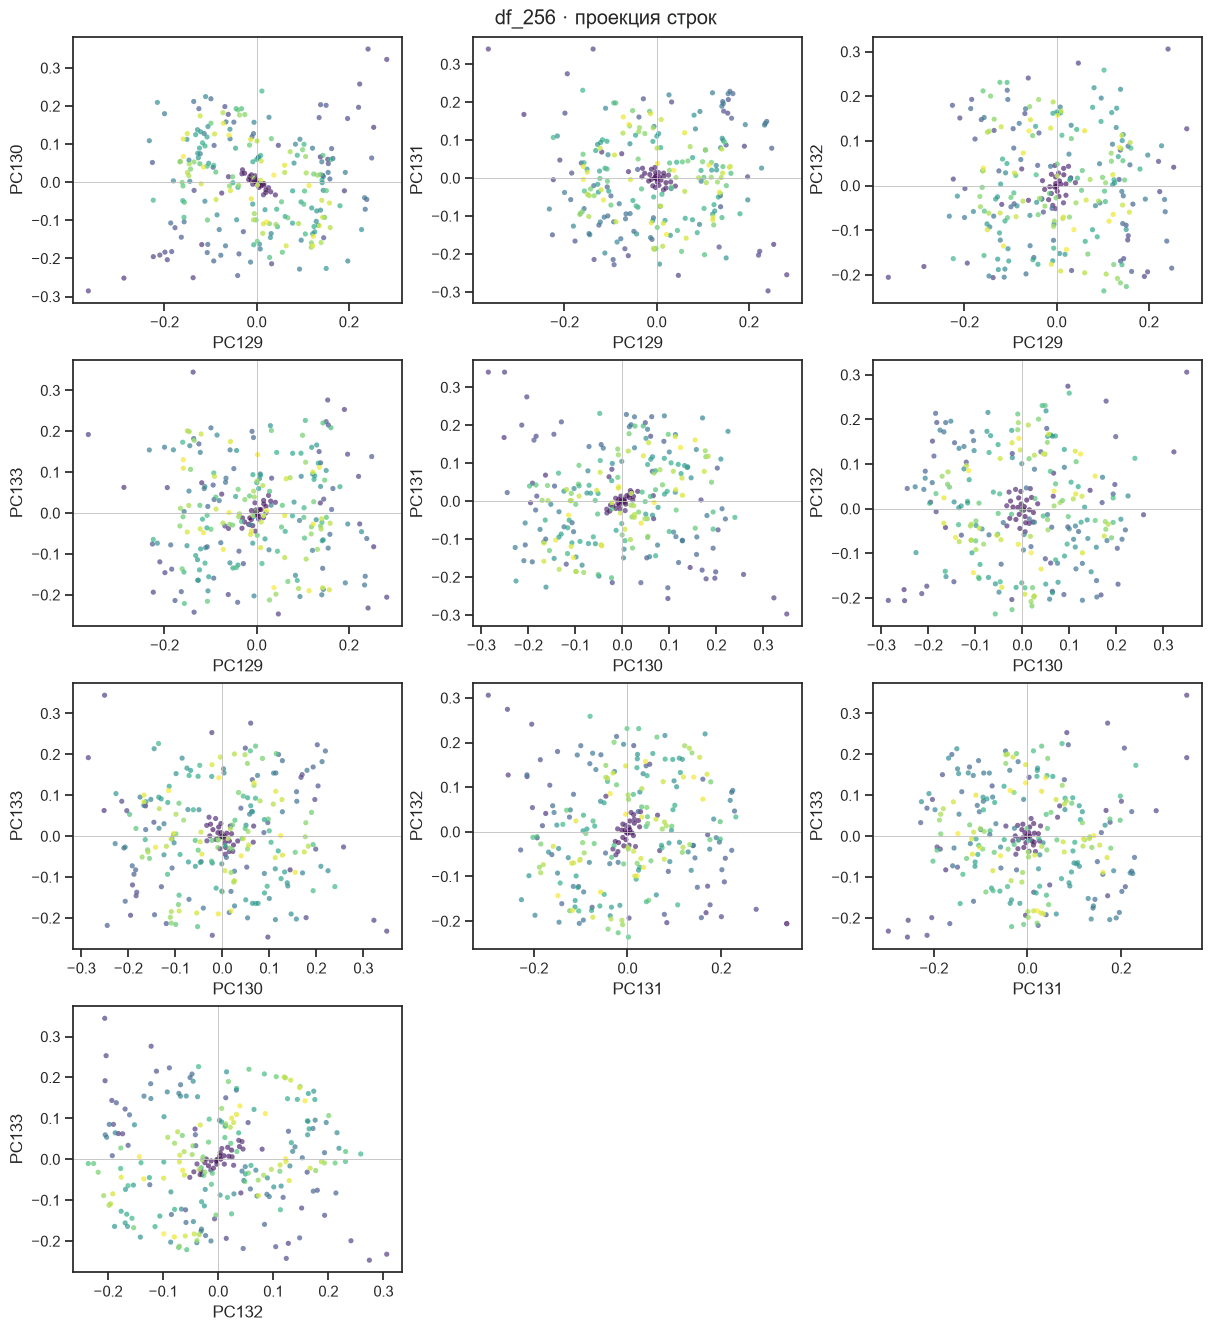

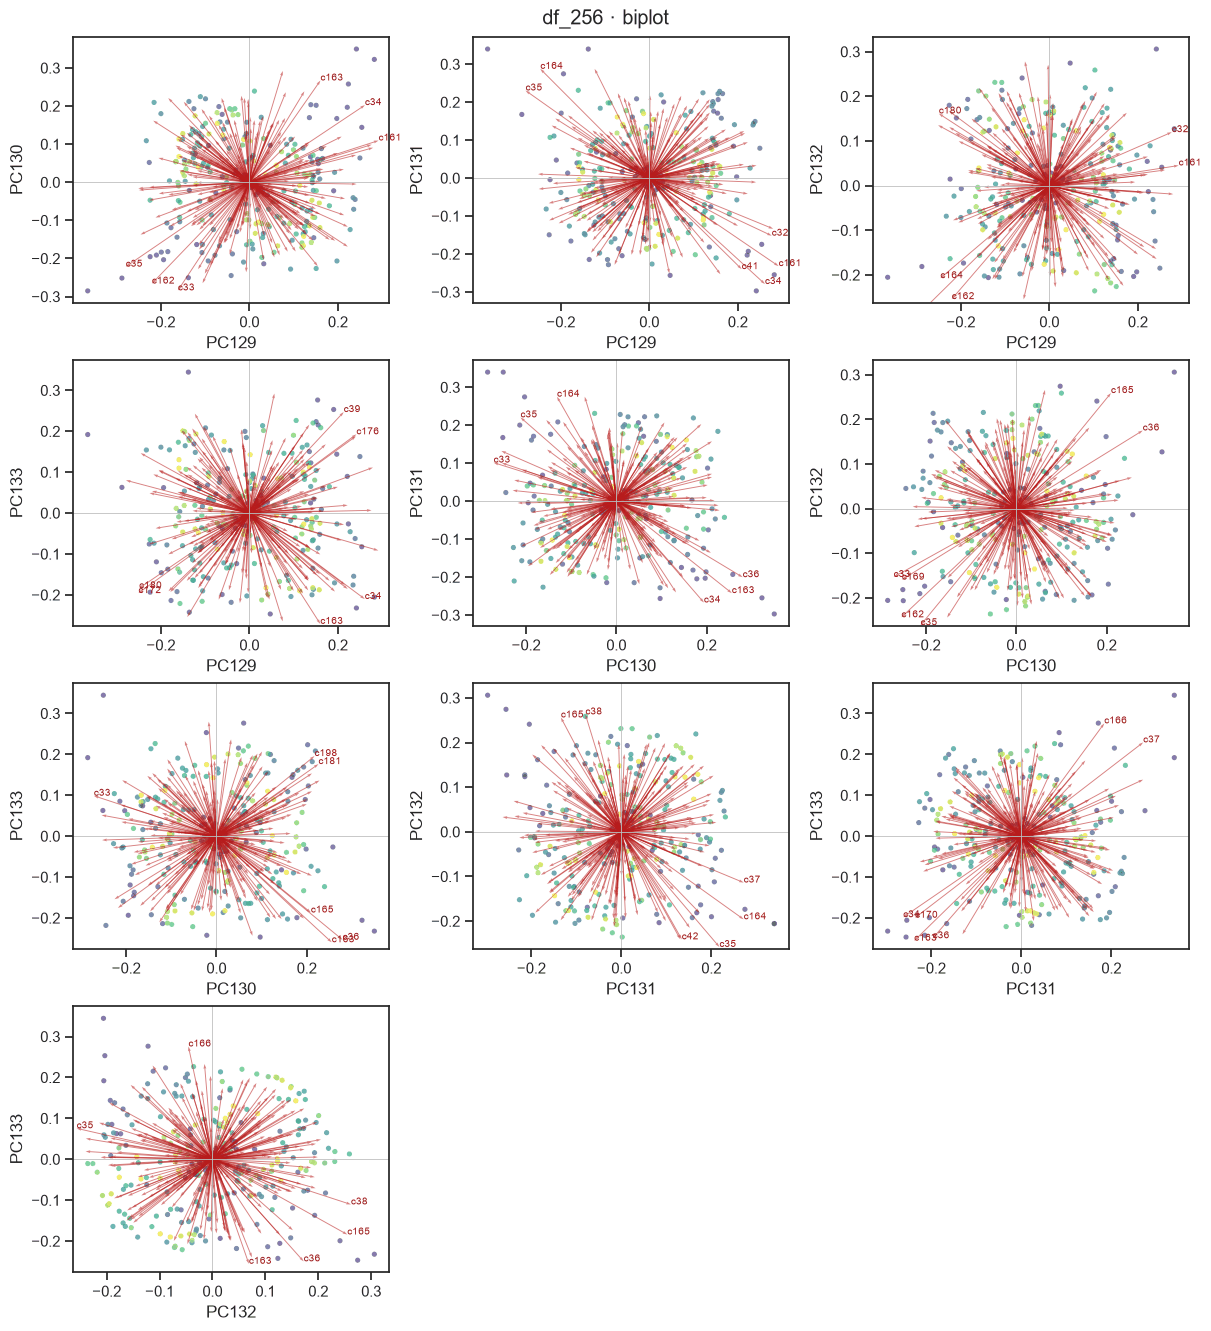

In [4]:
def standardize(values):
    values = np.asarray(values, dtype=np.float64)
    std = values.std(axis=0, ddof=1)
    if (std == 0).any():
        raise ValueError("PCA по корреляциям требует неконстантных признаков.")
    return (values - values.mean(axis=0)) / std

def correlation_pca(values):
    scaled = standardize(values)
    with threadpool_limits(limits=4):
        model = PCA(svd_solver="full").fit(scaled)
        scores = model.transform(scaled)
    loadings = model.components_.T * np.sqrt(model.explained_variance_)
    loadings[:, model.explained_variance_ < 1e-12] = 0
    scores[:, model.explained_variance_ < 1e-12] = 0
    return model, scores, loadings

def scree(model, title, broken_stick=None):
    eigenvalues = model.explained_variance_
    components = np.arange(1, len(eigenvalues) + 1)
    fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
    ax.plot(components, eigenvalues, marker=".", label="Собственные значения")
    if broken_stick is not None:
        ax.axhline(1, color="#b91c1c", linestyle="--", label="Кайзер (λ=1)")
        ax.plot(components, broken_stick * eigenvalues.sum(), ":", color="#15803d", label="Ломаная трость")
        ax.legend()
    ax.set(xlabel="Номер компоненты", ylabel="Собственное значение", title=title)
    plt.show()

def pc_panels(scores, loadings, features, components, title, *, arrows=False, colors=None):
    pairs = list(itertools.combinations(components, 2))
    columns = min(3, len(pairs))
    rows = int(np.ceil(len(pairs) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.0 * columns, 3.3 * rows),
                             squeeze=False, layout="constrained")
    for ax, (i, j) in zip(axes.flat, pairs):
        ax.axhline(0, lw=.6, c="0.75")
        ax.axvline(0, lw=.6, c="0.75")
        ax.scatter(scores[:, i], scores[:, j], s=1 if len(scores) > 100_000 else 14 if len(scores) < 300 else 4,
                   c=colors if colors is not None else np.arange(len(scores)),
                   cmap="tab10" if colors is not None else "viridis",
                   alpha=.10 if len(scores) > 100_000 else .65, linewidths=0)
        if arrows:
            vectors = loadings[:, [i, j]]
            span = max(np.abs(scores[:, [i, j]]).max(), 1e-10)
            scale = 0.8 * span / max(np.abs(vectors).max(), 1e-10)
            vectors = vectors * scale
            ax.quiver(np.zeros(len(vectors)), np.zeros(len(vectors)), *vectors.T,
                      scale=1, units="width", scale_units="xy", angles="xy",
                      width=.003, color="#b91c1c", alpha=.55)
            longest = np.argsort(np.linalg.norm(vectors, axis=1))[-6:]
            for index in longest:
                ax.annotate(features[index], vectors[index], fontsize=7, color="#991b1b")
        ax.set(xlabel=f"PC{i + 1}", ylabel=f"PC{j + 1}")
    for ax in list(axes.flat)[len(pairs):]:
        ax.set_visible(False)
    fig.suptitle(f"{title} · {'biplot' if arrows else 'проекция строк'}")
    plt.show()

pca_results = {}
for n, matrix in matrices.items():
    model, scores, loadings = correlation_pca(matrix)
    pca_results[n] = (model, scores, loadings)
    np.testing.assert_allclose(model.explained_variance_.sum(), n)
    feature_names = [f"c{i + 1}" for i in range(n)]
    scree(model, f"df_{n} · scree plot")
    ranges = [range(4)]
    if n == 256:
        ranges.append(range(128, 133))
    for components in ranges:
        for arrows in (False, True):
            pc_panels(scores, loadings, feature_names, components, f"df_{n}", arrows=arrows)

## Нелинейные проекции матриц

Для каждого метода используем начальные состояния 42 и 123, а затем те же
состояния после внешнего PCA. В признаковом пространстве исходные признаки
стандартизируются, для PCA используем до 10 компонент. Там, где вход содержит
4 или 2 признака, оставляем все доступные компоненты. В этих случаях PCA меняет
базис без существенной потери расстояний. Положение и ориентация проекций
условны, при сравнении важна относительная структура.

Для четырёх объектов PaCMAP получает по одной ближней, средней и дальней паре на объект. Пары определены по порядку расстояний.

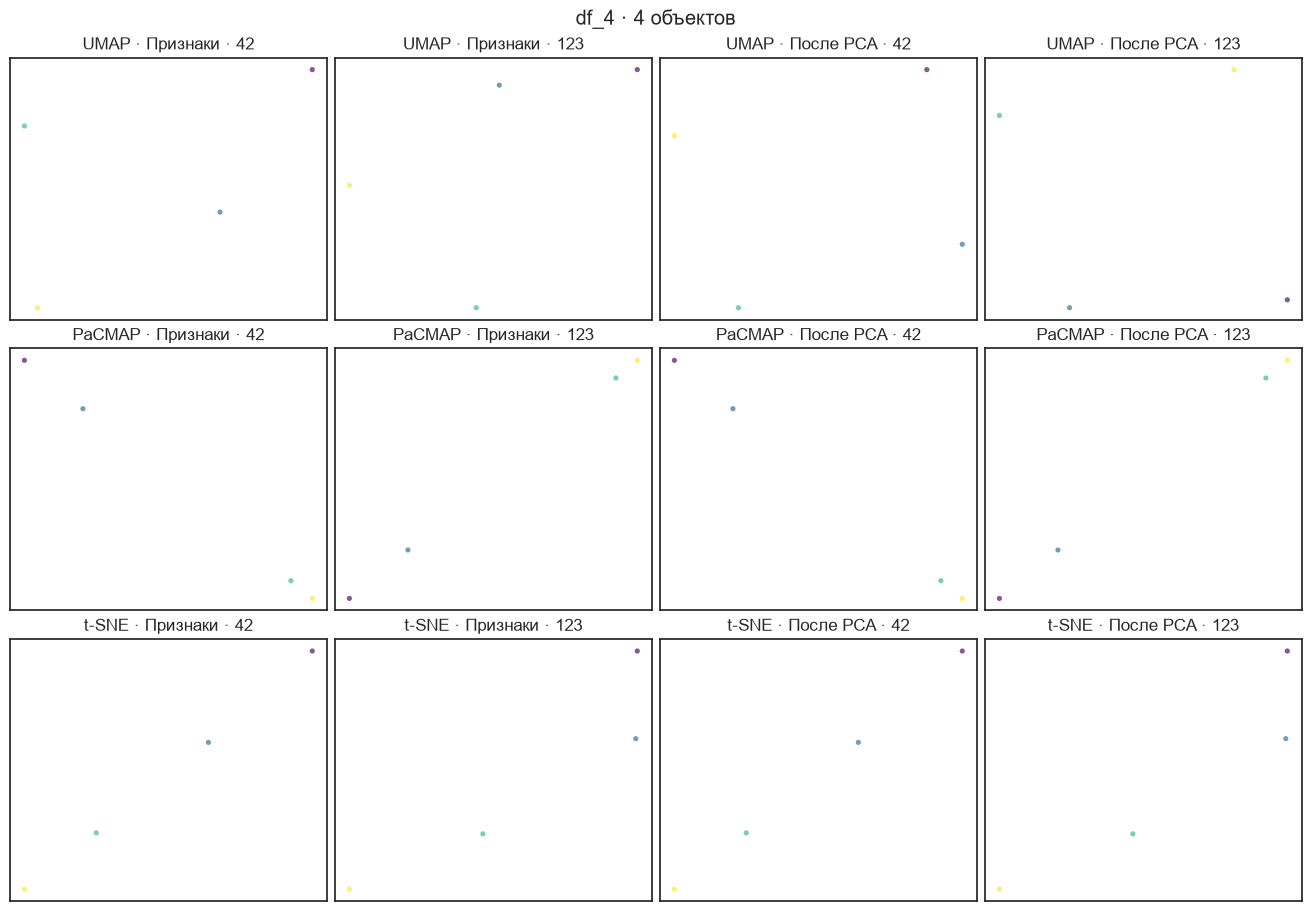

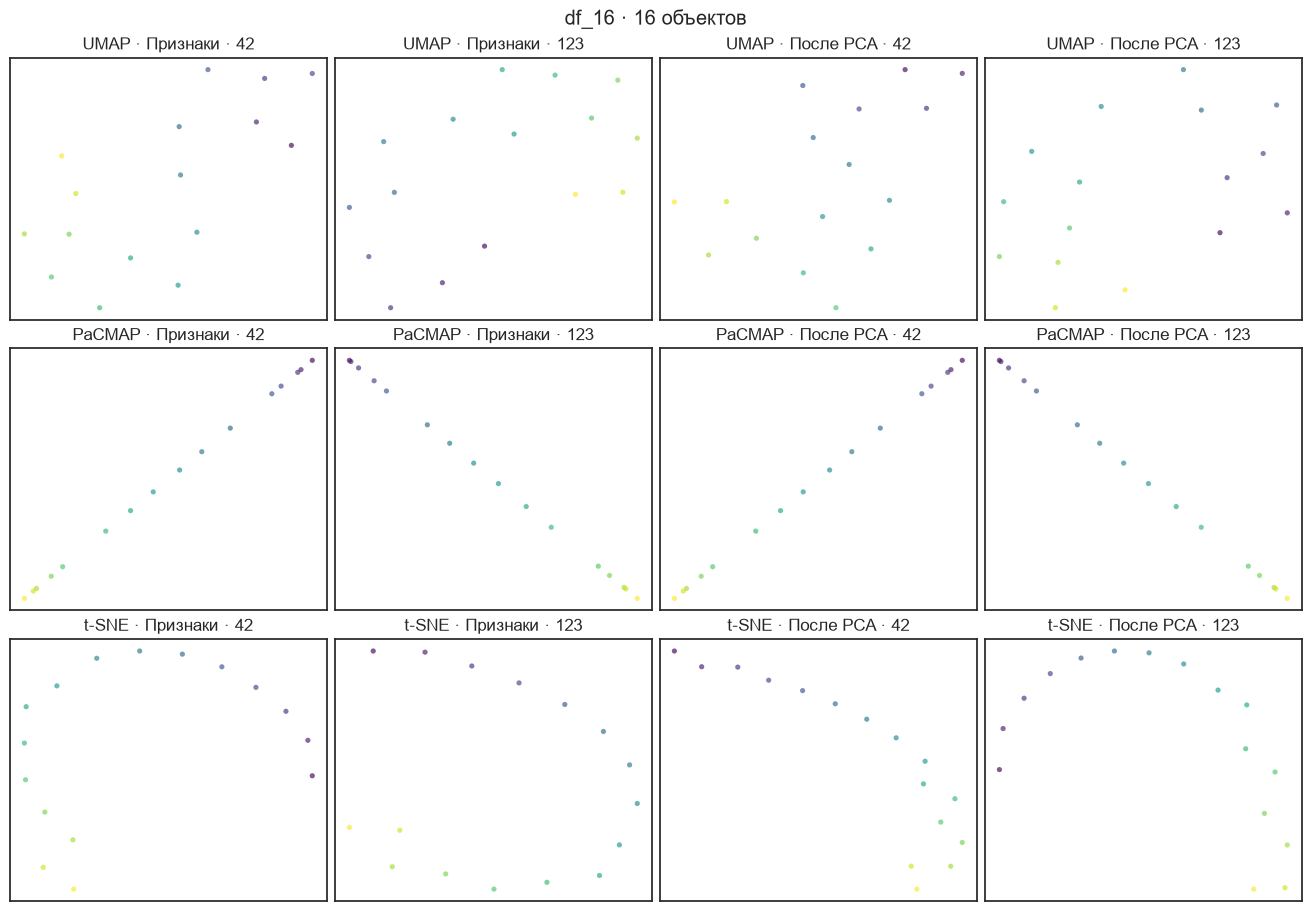

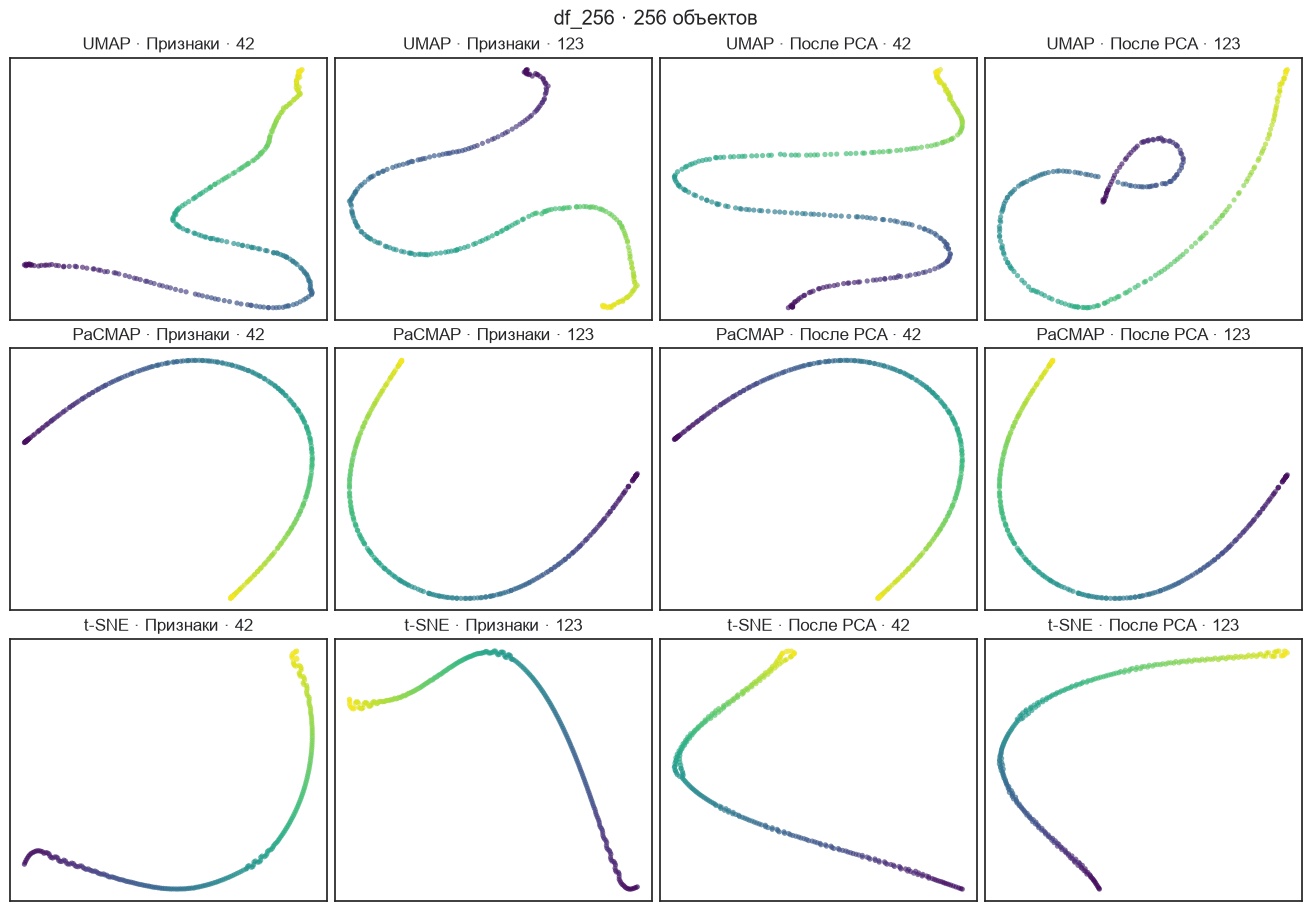

In [5]:
def tiny_pairs(X):
    distance = np.square(X[:, None] - X[None, :]).sum(axis=2)
    np.fill_diagonal(distance, np.inf)
    others = np.argsort(distance, axis=1)[:, :3]
    return {key: np.c_[np.arange(len(X)), others[:, rank]].astype(np.int32)
            for rank, key in enumerate(["pair_neighbors", "pair_MN", "pair_FP"])}

def nonlinear(X, name, seed):
    n = len(X)
    with threadpool_limits(limits=4):
        if name == "t-SNE":
            return TSNE(
                init="random", perplexity=min(30, max(1, (n - 1) // 3)),
                max_iter=500, random_state=seed, n_jobs=4,
            ).fit_transform(X)
        if name == "UMAP":
            return umap.UMAP(
                n_neighbors=min(15, n - 1), init="random", n_epochs=220,
                n_jobs=1, random_state=seed, compatibility_layout=True,
            ).fit_transform(X)
        return pacmap.PaCMAP(
            n_neighbors=min(12, max(1, n // 4)), apply_pca=False, random_state=seed,
            num_iters=(100, 100, 200),
            **(tiny_pairs(X) if n == 4 else {}),
        ).fit_transform(X.copy(), init="random")

def embeddings(values, scores, title, colors=None):
    base = np.ascontiguousarray(standardize(values), dtype=np.float32)
    reduced = np.ascontiguousarray(scores[:, :min(10, scores.shape[1])], dtype=np.float32)
    cases = [(data, kind, seed) for data, kind in [(base, "Признаки"), (reduced, "После PCA")]
             for seed in (42, 123)]
    fig, axes = plt.subplots(3, 4, figsize=(13, 9), layout="constrained")
    for method, row in zip(["UMAP", "PaCMAP", "t-SNE"], axes):
        for ax, (data, kind, seed) in zip(row, cases):
            projected = nonlinear(data, method, seed)
            assert projected.shape == (len(data), 2) and np.isfinite(projected).all()
            ax.scatter(*projected.T, s=14 if len(data) < 300 else 5,
                       c=colors if colors is not None else np.arange(len(data)),
                       cmap="tab10" if colors is not None else "viridis",
                       linewidths=0, alpha=.65)
            ax.set(title=f"{method} · {kind} · {seed}", xticks=[], yticks=[])
    fig.suptitle(f"{title} · {len(base):,} объектов")
    plt.show()

for n, matrix in matrices.items():
    embeddings(matrix, pca_results[n][1], f"df_{n}")

## df_256v. Десять точек у каждой ячейки

Выбираем дисперсию d=10 по каждой оси, поэтому cluster_std=√10.
Класс каждой точки равен значению соответствующей ячейки. PCA использует
все 655 360 точек и возвращает две компоненты, поскольку признаков два.
На scree plot и двумерных проекциях PCA использованы все точки.

Для UMAP, PaCMAP и t-SNE по умолчанию используем по 12 000 точек
в воспроизводимой стратифицированной подвыборке. Чтобы запустить проекции
на полном наборе, перед запуском ноутбука установите переменную среды
DF256V_EMBEDDING_SIZE=655360. Полный расчёт требует значительно больше памяти и времени.

class
0    408960
1    246400
Name: точки, dtype: int64

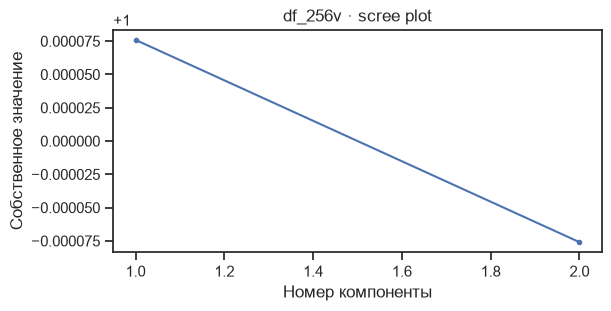

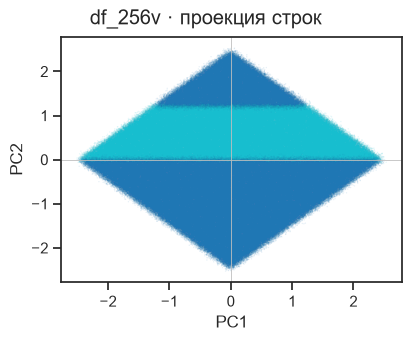

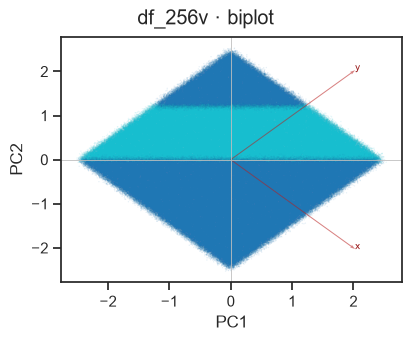

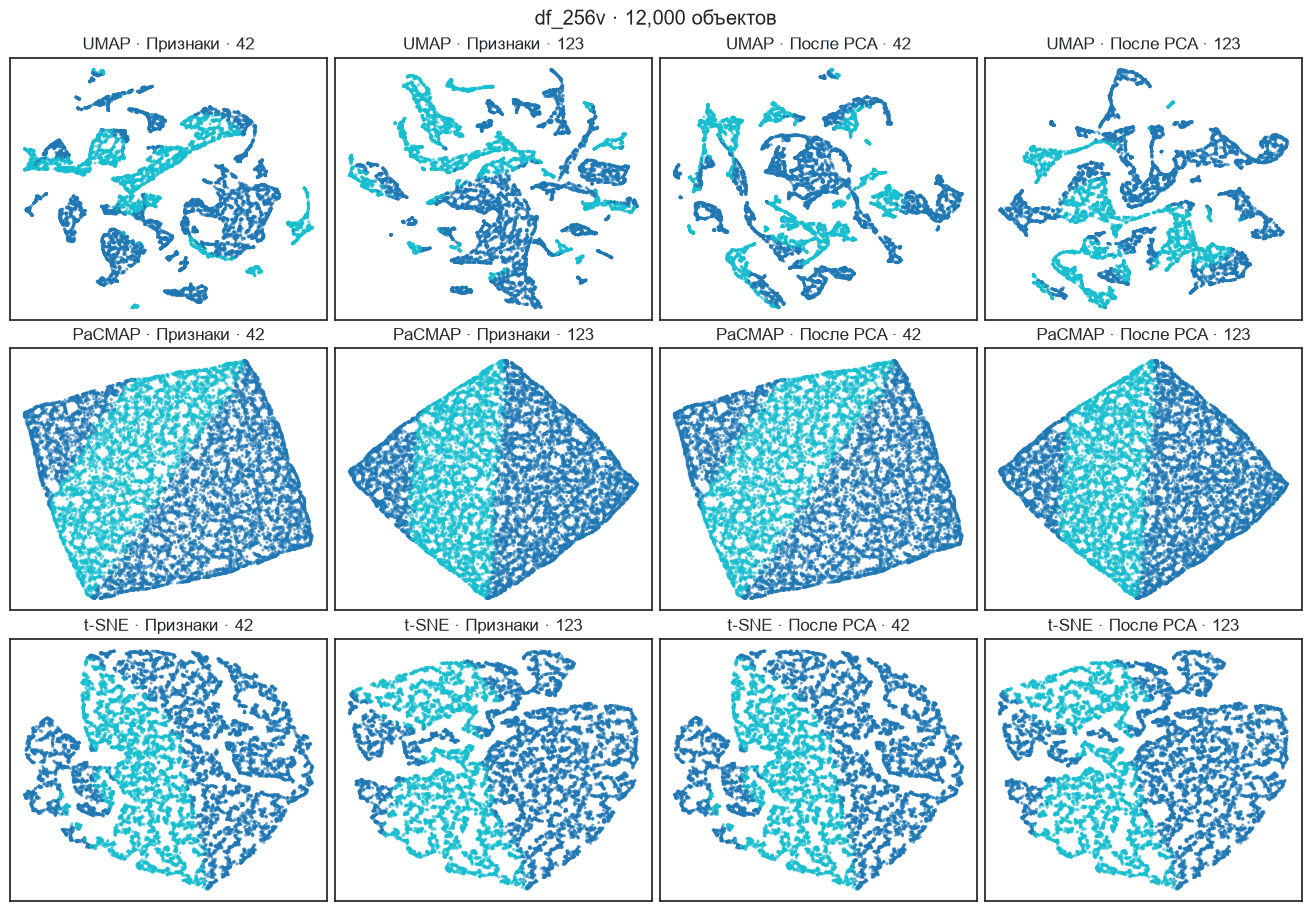

In [6]:
coordinates = np.indices(matrices[256].shape).reshape(2, -1).T
blob_X, origin = make_blobs(
    n_samples=[10] * len(coordinates), centers=coordinates, cluster_std=np.sqrt(10),
    random_state=SEED,
)
blob_y = matrices[256].ravel()[origin]
df_256v = pd.DataFrame(blob_X, columns=["x", "y"]).assign(**{"class": blob_y})
assert len(df_256v) == 655_360 and (np.bincount(origin) == 10).all()
display(df_256v["class"].value_counts().rename("точки"))

blob_model, blob_scores, blob_loadings = correlation_pca(blob_X)
scree(blob_model, "df_256v · scree plot")
limit = int(os.environ.get("DF256V_EMBEDDING_SIZE", "12000"))
if not 4 <= limit <= len(blob_X):
    raise ValueError("DF256V_EMBEDDING_SIZE должен быть от 4 до 655360.")
indices = np.arange(len(blob_X))
if limit < len(blob_X):
    _, selected = train_test_split(indices, test_size=limit, stratify=blob_y, random_state=SEED)
else:
    selected = indices
for arrows in (False, True):
    pc_panels(blob_scores, blob_loadings, ["x", "y"], range(2),
              "df_256v", arrows=arrows, colors=blob_y)

embeddings(blob_X[selected], blob_scores[selected], "df_256v", colors=blob_y[selected])

## Dry Bean Dataset

Классификация семи сортов фасоли по 16 числовым признакам формы и размера.
Загружаем CSV из [копии на Kaggle](https://www.kaggle.com/datasets/chetalipushkarna/dry-bean-dataset).
Первоисточник: M. Koklu и I. A. Ozkan, [Dry Bean Dataset, UCI](https://doi.org/10.24432/C50S4B),
CC BY 4.0. Статистики, корреляции и парные графики рассчитаны на всём датасете.

,исходные строки,исходные столбцы,исходные признаки,выбранные признаки,классы,"строки с пропусками, %",строки после очистки
0,13611,17,16,16,7,0.0,13611


,до,после
class,,
BARBUNYA,1322,1322
BOMBAY,522,522
CALI,1630,1630
DERMASON,3546,3546
HOROZ,1928,1928
SEKER,2027,2027
SIRA,2636,2636


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000,13611.000
mean,53048.285,855.283,320.142,202.271,1.583,0.751,53768.200,253.064,0.750,0.987,0.873,0.800,0.007,0.002,0.644,0.995
std,29324.096,214.290,85.694,44.970,0.247,0.092,29774.916,59.177,0.049,0.005,0.060,0.062,0.001,0.001,0.099,0.004
min,20420.000,524.736,183.601,122.513,1.025,0.219,20684.000,161.244,0.555,0.919,0.490,0.641,0.003,0.001,0.410,0.948
25%,36328.000,703.524,253.304,175.848,1.432,0.716,36714.500,215.068,0.719,0.986,0.832,0.762,0.006,0.001,0.581,0.994
50%,44652.000,794.941,296.883,192.432,1.551,0.764,45178.000,238.438,0.760,0.988,0.883,0.801,0.007,0.002,0.642,0.996
75%,61332.000,977.213,376.495,217.032,1.707,0.810,62294.000,279.446,0.787,0.990,0.917,0.834,0.007,0.002,0.696,0.998
max,254616.000,1985.370,738.860,460.198,2.430,0.911,263261.000,569.374,0.866,0.995,0.991,0.987,0.010,0.004,0.975,1.000


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.967000,0.932000,0.952000,0.242000,0.267000,1.000000,0.985000,0.054000,-0.197000,-0.358000,-0.268000,-0.848000,-0.639000,-0.272000,-0.356000
Perimeter,0.967000,1.000000,0.977000,0.913000,0.385000,0.391000,0.968000,0.991000,-0.021000,-0.304000,-0.548000,-0.407000,-0.865000,-0.768000,-0.408000,-0.429000
MajorAxisLength,0.932000,0.977000,1.000000,0.826000,0.550000,0.542000,0.933000,0.962000,-0.078000,-0.284000,-0.596000,-0.568000,-0.774000,-0.859000,-0.568000,-0.483000
MinorAxisLength,0.952000,0.913000,0.826000,1.000000,-0.009000,0.020000,0.951000,0.949000,0.146000,-0.156000,-0.210000,-0.015000,-0.947000,-0.471000,-0.019000,-0.264000
AspectRation,0.242000,0.385000,0.550000,-0.009000,1.000000,0.924000,0.243000,0.304000,-0.370000,-0.268000,-0.767000,-0.988000,0.025000,-0.838000,-0.979000,-0.449000
Eccentricity,0.267000,0.391000,0.542000,0.020000,0.924000,1.000000,0.269000,0.319000,-0.319000,-0.298000,-0.722000,-0.970000,0.020000,-0.860000,-0.981000,-0.449000
ConvexArea,1.000000,0.968000,0.933000,0.951000,0.243000,0.269000,1.000000,0.985000,0.053000,-0.206000,-0.362000,-0.270000,-0.848000,-0.641000,-0.274000,-0.362000
EquivDiameter,0.985000,0.991000,0.962000,0.949000,0.304000,0.319000,0.985000,1.000000,0.028000,-0.232000,-0.436000,-0.328000,-0.893000,-0.713000,-0.330000,-0.393000
Extent,0.054000,-0.021000,-0.078000,0.146000,-0.370000,-0.319000,0.053000,0.028000,1.000000,0.191000,0.344000,0.354000,-0.142000,0.238000,0.348000,0.149000
Solidity,-0.197000,-0.304000,-0.284000,-0.156000,-0.268000,-0.298000,-0.206000,-0.232000,0.191000,1.000000,0.607000,0.304000,0.153000,0.344000,0.308000,0.702000


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.931000,0.880000,0.863000,0.072000,0.066000,1.000000,0.998000,0.021000,0.022000,-0.196000,-0.072000,-0.861000,-0.549000,-0.071000,-0.073000
Perimeter,0.931000,1.000000,0.872000,0.754000,0.172000,0.163000,0.938000,0.932000,-0.063000,-0.238000,-0.536000,-0.173000,-0.756000,-0.602000,-0.172000,-0.126000
MajorAxisLength,0.880000,0.872000,1.000000,0.525000,0.534000,0.518000,0.879000,0.882000,-0.102000,0.013000,-0.310000,-0.533000,-0.535000,-0.873000,-0.531000,-0.084000
MinorAxisLength,0.863000,0.754000,0.525000,1.000000,-0.435000,-0.436000,0.863000,0.864000,0.147000,0.017000,-0.030000,0.436000,-0.993000,-0.069000,0.437000,-0.081000
AspectRation,0.072000,0.172000,0.534000,-0.435000,1.000000,0.972000,0.072000,0.074000,-0.253000,-0.006000,-0.299000,-0.996000,0.422000,-0.855000,-0.993000,-0.014000
Eccentricity,0.066000,0.163000,0.518000,-0.436000,0.972000,1.000000,0.066000,0.068000,-0.250000,-0.004000,-0.291000,-0.988000,0.419000,-0.860000,-0.992000,-0.006000
ConvexArea,1.000000,0.938000,0.879000,0.863000,0.072000,0.066000,1.000000,0.998000,0.015000,-0.006000,-0.216000,-0.072000,-0.860000,-0.549000,-0.071000,-0.084000
EquivDiameter,0.998000,0.932000,0.882000,0.864000,0.074000,0.068000,0.998000,1.000000,0.021000,0.024000,-0.197000,-0.074000,-0.867000,-0.555000,-0.073000,-0.076000
Extent,0.021000,-0.063000,-0.102000,0.147000,-0.253000,-0.250000,0.015000,0.021000,1.000000,0.234000,0.215000,0.253000,-0.142000,0.199000,0.253000,-0.007000
Solidity,0.022000,-0.238000,0.013000,0.017000,-0.006000,-0.004000,-0.006000,0.024000,0.234000,1.000000,0.716000,0.017000,-0.036000,0.001000,0.017000,0.399000


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.978000,0.916000,0.845000,0.401000,0.398000,0.999000,0.999000,0.059000,-0.166000,-0.304000,-0.406000,-0.823000,-0.718000,-0.406000,-0.264000
Perimeter,0.978000,1.000000,0.962000,0.744000,0.540000,0.531000,0.982000,0.979000,0.032000,-0.284000,-0.493000,-0.547000,-0.718000,-0.814000,-0.546000,-0.381000
MajorAxisLength,0.916000,0.962000,1.000000,0.564000,0.734000,0.721000,0.920000,0.920000,0.043000,-0.284000,-0.572000,-0.737000,-0.536000,-0.929000,-0.735000,-0.418000
MinorAxisLength,0.845000,0.744000,0.564000,1.000000,-0.146000,-0.141000,0.839000,0.842000,0.058000,-0.005000,0.117000,0.138000,-0.994000,-0.253000,0.137000,-0.046000
AspectRation,0.401000,0.540000,0.734000,-0.146000,1.000000,0.978000,0.411000,0.409000,0.006000,-0.336000,-0.781000,-0.996000,0.174000,-0.908000,-0.993000,-0.465000
Eccentricity,0.398000,0.531000,0.721000,-0.141000,0.978000,1.000000,0.407000,0.407000,-0.003000,-0.327000,-0.760000,-0.990000,0.169000,-0.918000,-0.993000,-0.443000
ConvexArea,0.999000,0.982000,0.920000,0.839000,0.411000,0.407000,1.000000,0.998000,0.049000,-0.205000,-0.326000,-0.418000,-0.815000,-0.725000,-0.417000,-0.295000
EquivDiameter,0.999000,0.979000,0.920000,0.842000,0.409000,0.407000,0.998000,1.000000,0.061000,-0.165000,-0.308000,-0.415000,-0.823000,-0.727000,-0.415000,-0.267000
Extent,0.059000,0.032000,0.043000,0.058000,0.006000,-0.003000,0.049000,0.061000,1.000000,0.227000,0.113000,0.007000,-0.074000,-0.021000,0.008000,0.170000
Solidity,-0.166000,-0.284000,-0.284000,-0.005000,-0.336000,-0.327000,-0.205000,-0.165000,0.227000,1.000000,0.623000,0.372000,-0.060000,0.339000,0.370000,0.825000


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.975000,0.930000,0.912000,0.198000,0.218000,0.999000,0.999000,-0.013000,0.020000,-0.047000,-0.210000,-0.899000,-0.684000,-0.213000,-0.079000
Perimeter,0.975000,1.000000,0.967000,0.830000,0.348000,0.364000,0.978000,0.976000,-0.059000,-0.072000,-0.265000,-0.363000,-0.814000,-0.785000,-0.365000,-0.159000
MajorAxisLength,0.930000,0.967000,1.000000,0.705000,0.540000,0.553000,0.932000,0.933000,-0.046000,-0.035000,-0.308000,-0.551000,-0.690000,-0.897000,-0.553000,-0.151000
MinorAxisLength,0.912000,0.830000,0.705000,1.000000,-0.214000,-0.188000,0.912000,0.912000,0.018000,0.015000,0.232000,0.197000,-0.993000,-0.348000,0.193000,-0.058000
AspectRation,0.198000,0.348000,0.540000,-0.214000,1.000000,0.986000,0.201000,0.204000,-0.083000,-0.069000,-0.706000,-0.994000,0.229000,-0.828000,-0.992000,-0.139000
Eccentricity,0.218000,0.364000,0.553000,-0.188000,0.986000,1.000000,0.221000,0.226000,-0.074000,-0.071000,-0.687000,-0.992000,0.201000,-0.852000,-0.994000,-0.147000
ConvexArea,0.999000,0.978000,0.932000,0.912000,0.201000,0.221000,1.000000,0.998000,-0.022000,-0.028000,-0.067000,-0.217000,-0.895000,-0.688000,-0.220000,-0.120000
EquivDiameter,0.999000,0.976000,0.933000,0.912000,0.204000,0.226000,0.998000,1.000000,-0.013000,0.018000,-0.050000,-0.217000,-0.902000,-0.693000,-0.220000,-0.081000
Extent,-0.013000,-0.059000,-0.046000,0.018000,-0.083000,-0.074000,-0.022000,-0.013000,1.000000,0.181000,0.214000,0.089000,-0.027000,0.066000,0.088000,0.126000
Solidity,0.020000,-0.072000,-0.035000,0.015000,-0.069000,-0.071000,-0.028000,0.018000,0.181000,1.000000,0.412000,0.140000,-0.078000,0.094000,0.140000,0.860000


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.971000,0.924000,0.908000,0.132000,0.147000,1.000000,0.999000,-0.014000,0.227000,-0.037000,-0.137000,-0.902000,-0.668000,-0.139000,0.044000
Perimeter,0.971000,1.000000,0.946000,0.835000,0.250000,0.258000,0.975000,0.972000,-0.057000,0.046000,-0.268000,-0.255000,-0.828000,-0.741000,-0.256000,-0.049000
MajorAxisLength,0.924000,0.946000,1.000000,0.683000,0.499000,0.506000,0.925000,0.925000,-0.084000,0.163000,-0.252000,-0.503000,-0.679000,-0.896000,-0.504000,-0.004000
MinorAxisLength,0.908000,0.835000,0.683000,1.000000,-0.289000,-0.272000,0.908000,0.909000,0.066000,0.246000,0.193000,0.285000,-0.995000,-0.309000,0.283000,0.063000
AspectRation,0.132000,0.250000,0.499000,-0.289000,1.000000,0.982000,0.134000,0.133000,-0.188000,-0.081000,-0.568000,-0.997000,0.293000,-0.811000,-0.995000,-0.084000
Eccentricity,0.147000,0.258000,0.506000,-0.272000,0.982000,1.000000,0.149000,0.148000,-0.182000,-0.063000,-0.540000,-0.992000,0.272000,-0.826000,-0.995000,-0.064000
ConvexArea,1.000000,0.975000,0.925000,0.908000,0.134000,0.149000,1.000000,0.999000,-0.017000,0.208000,-0.052000,-0.139000,-0.900000,-0.669000,-0.141000,0.034000
EquivDiameter,0.999000,0.972000,0.925000,0.909000,0.133000,0.148000,0.999000,1.000000,-0.012000,0.228000,-0.037000,-0.138000,-0.905000,-0.672000,-0.140000,0.044000
Extent,-0.014000,-0.057000,-0.084000,0.066000,-0.188000,-0.182000,-0.017000,-0.012000,1.000000,0.137000,0.206000,0.188000,-0.071000,0.142000,0.188000,0.092000
Solidity,0.227000,0.046000,0.163000,0.246000,-0.081000,-0.063000,0.208000,0.228000,0.137000,1.000000,0.731000,0.089000,-0.261000,-0.069000,0.087000,0.508000


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.961000,0.915000,0.881000,0.159000,0.173000,0.999000,0.999000,-0.018000,0.022000,-0.212000,-0.177000,-0.895000,-0.648000,-0.179000,-0.058000
Perimeter,0.961000,1.000000,0.940000,0.784000,0.297000,0.304000,0.964000,0.962000,-0.077000,-0.066000,-0.470000,-0.316000,-0.799000,-0.737000,-0.318000,-0.069000
MajorAxisLength,0.915000,0.940000,1.000000,0.622000,0.541000,0.545000,0.910000,0.919000,-0.072000,0.104000,-0.412000,-0.556000,-0.653000,-0.892000,-0.557000,0.048000
MinorAxisLength,0.881000,0.784000,0.622000,1.000000,-0.319000,-0.301000,0.888000,0.878000,0.047000,-0.153000,0.047000,0.296000,-0.990000,-0.238000,0.293000,-0.258000
AspectRation,0.159000,0.297000,0.541000,-0.319000,1.000000,0.981000,0.146000,0.169000,-0.139000,0.274000,-0.561000,-0.993000,0.276000,-0.829000,-0.990000,0.321000
Eccentricity,0.173000,0.304000,0.545000,-0.301000,0.981000,1.000000,0.159000,0.183000,-0.135000,0.284000,-0.547000,-0.989000,0.256000,-0.848000,-0.992000,0.325000
ConvexArea,0.999000,0.964000,0.910000,0.888000,0.146000,0.159000,1.000000,0.998000,-0.020000,-0.025000,-0.225000,-0.167000,-0.898000,-0.641000,-0.169000,-0.098000
EquivDiameter,0.999000,0.962000,0.919000,0.878000,0.169000,0.183000,0.998000,1.000000,-0.019000,0.023000,-0.215000,-0.186000,-0.896000,-0.661000,-0.189000,-0.058000
Extent,-0.018000,-0.077000,-0.072000,0.047000,-0.139000,-0.135000,-0.020000,-0.019000,1.000000,0.059000,0.225000,0.142000,-0.046000,0.115000,0.141000,-0.003000
Solidity,0.022000,-0.066000,0.104000,-0.153000,0.274000,0.284000,-0.025000,0.023000,0.059000,1.000000,0.303000,-0.206000,0.066000,-0.159000,-0.207000,0.838000


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.957000,0.924000,0.836000,0.426000,0.392000,1.000000,0.999000,-0.133000,0.047000,-0.204000,-0.420000,-0.830000,-0.743000,-0.417000,-0.100000
Perimeter,0.957000,1.000000,0.912000,0.765000,0.472000,0.431000,0.962000,0.957000,-0.195000,-0.180000,-0.476000,-0.467000,-0.756000,-0.757000,-0.463000,-0.213000
MajorAxisLength,0.924000,0.912000,1.000000,0.565000,0.739000,0.699000,0.924000,0.924000,-0.223000,0.032000,-0.288000,-0.733000,-0.561000,-0.935000,-0.730000,-0.139000
MinorAxisLength,0.836000,0.765000,0.565000,1.000000,-0.136000,-0.155000,0.836000,0.838000,0.027000,0.043000,-0.036000,0.141000,-0.997000,-0.272000,0.143000,-0.045000
AspectRation,0.426000,0.472000,0.739000,-0.136000,1.000000,0.964000,0.426000,0.426000,-0.291000,0.001000,-0.319000,-0.996000,0.140000,-0.903000,-0.993000,-0.134000
Eccentricity,0.392000,0.431000,0.699000,-0.155000,0.964000,1.000000,0.392000,0.394000,-0.273000,0.027000,-0.274000,-0.982000,0.158000,-0.899000,-0.987000,-0.122000
ConvexArea,1.000000,0.962000,0.924000,0.836000,0.426000,0.392000,1.000000,0.999000,-0.138000,0.021000,-0.224000,-0.420000,-0.829000,-0.743000,-0.417000,-0.116000
EquivDiameter,0.999000,0.957000,0.924000,0.838000,0.426000,0.394000,0.999000,1.000000,-0.133000,0.051000,-0.201000,-0.421000,-0.834000,-0.747000,-0.418000,-0.100000
Extent,-0.133000,-0.195000,-0.223000,0.027000,-0.291000,-0.273000,-0.138000,-0.133000,1.000000,0.190000,0.259000,0.291000,-0.031000,0.267000,0.290000,0.167000
Solidity,0.047000,-0.180000,0.032000,0.043000,0.001000,0.027000,0.021000,0.051000,0.190000,1.000000,0.772000,0.006000,-0.071000,-0.027000,0.003000,0.638000


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.971000,0.913000,0.809000,0.395000,0.391000,1.000000,0.999000,-0.115000,0.077000,-0.234000,-0.397000,-0.801000,-0.716000,-0.397000,-0.120000
Perimeter,0.971000,1.000000,0.949000,0.701000,0.521000,0.514000,0.974000,0.970000,-0.185000,-0.056000,-0.459000,-0.524000,-0.689000,-0.799000,-0.523000,-0.189000
MajorAxisLength,0.913000,0.949000,1.000000,0.502000,0.734000,0.726000,0.914000,0.912000,-0.163000,0.002000,-0.473000,-0.735000,-0.492000,-0.933000,-0.734000,-0.172000
MinorAxisLength,0.809000,0.701000,0.502000,1.000000,-0.217000,-0.214000,0.807000,0.812000,-0.015000,0.128000,0.171000,0.212000,-0.996000,-0.182000,0.212000,-0.062000
AspectRation,0.395000,0.521000,0.734000,-0.217000,1.000000,0.986000,0.398000,0.392000,-0.174000,-0.099000,-0.670000,-0.997000,0.226000,-0.911000,-0.995000,-0.147000
Eccentricity,0.391000,0.514000,0.726000,-0.214000,0.986000,1.000000,0.395000,0.390000,-0.167000,-0.088000,-0.652000,-0.994000,0.222000,-0.919000,-0.996000,-0.137000
ConvexArea,1.000000,0.974000,0.914000,0.807000,0.398000,0.395000,1.000000,0.999000,-0.120000,0.049000,-0.249000,-0.401000,-0.797000,-0.718000,-0.401000,-0.138000
EquivDiameter,0.999000,0.970000,0.912000,0.812000,0.392000,0.390000,0.999000,1.000000,-0.114000,0.079000,-0.231000,-0.395000,-0.805000,-0.716000,-0.394000,-0.119000
Extent,-0.115000,-0.185000,-0.163000,-0.015000,-0.174000,-0.167000,-0.120000,-0.114000,1.000000,0.187000,0.329000,0.175000,0.008000,0.179000,0.175000,0.106000
Solidity,0.077000,-0.056000,0.002000,0.128000,-0.099000,-0.088000,0.049000,0.079000,0.187000,1.000000,0.521000,0.122000,-0.167000,0.053000,0.121000,0.641000


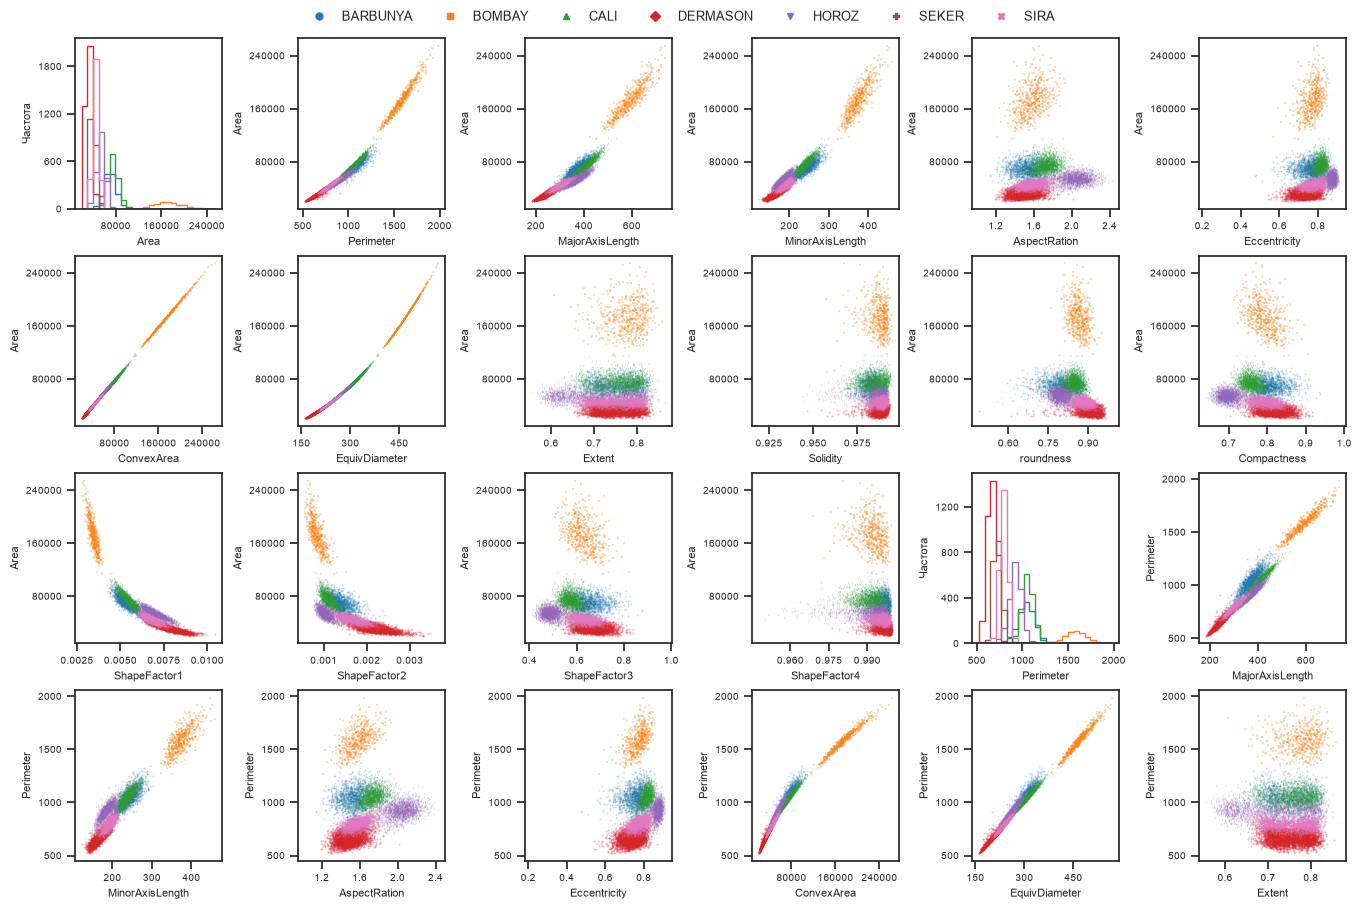

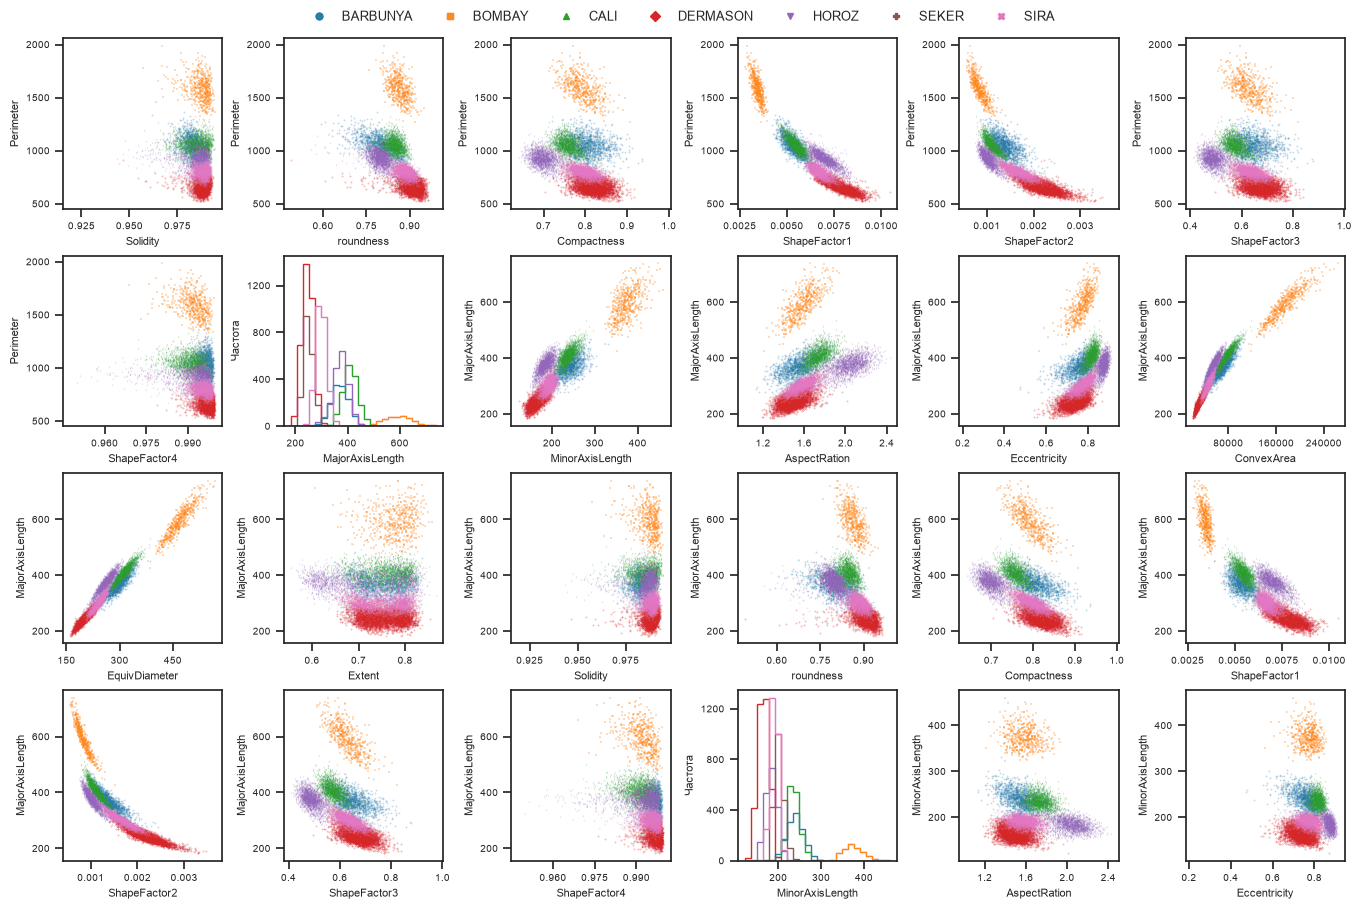

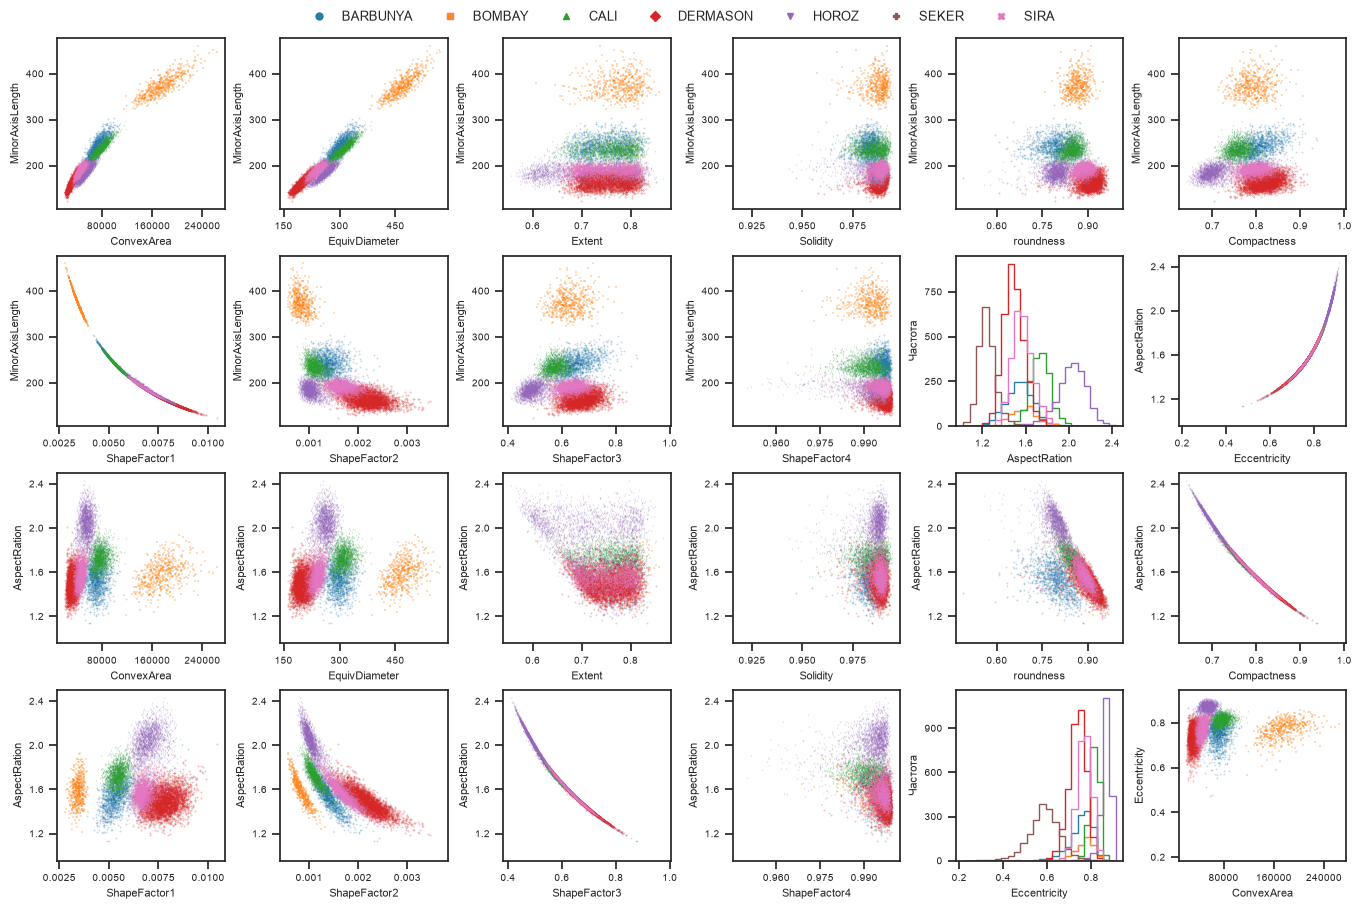

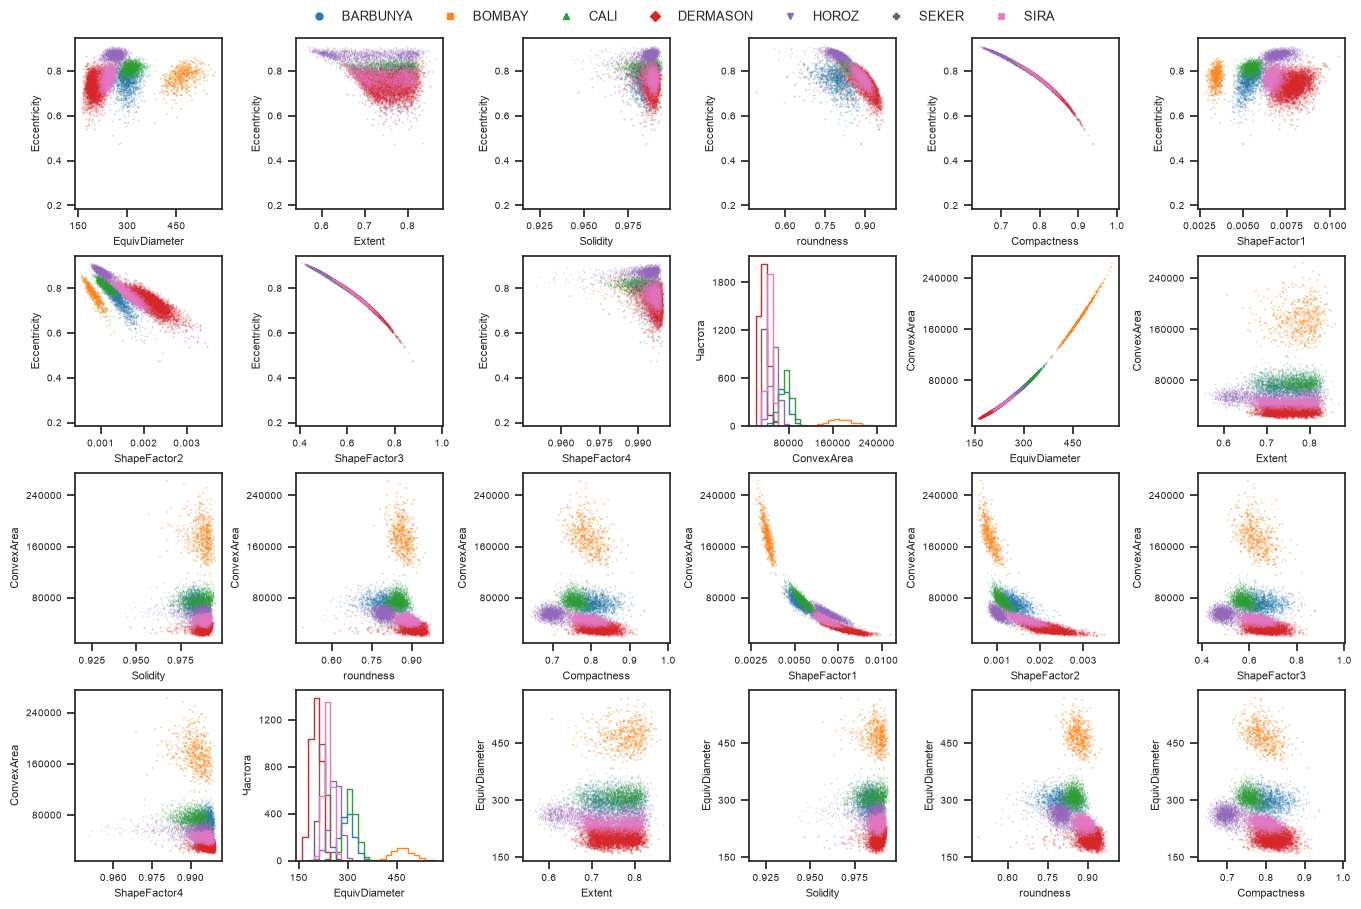

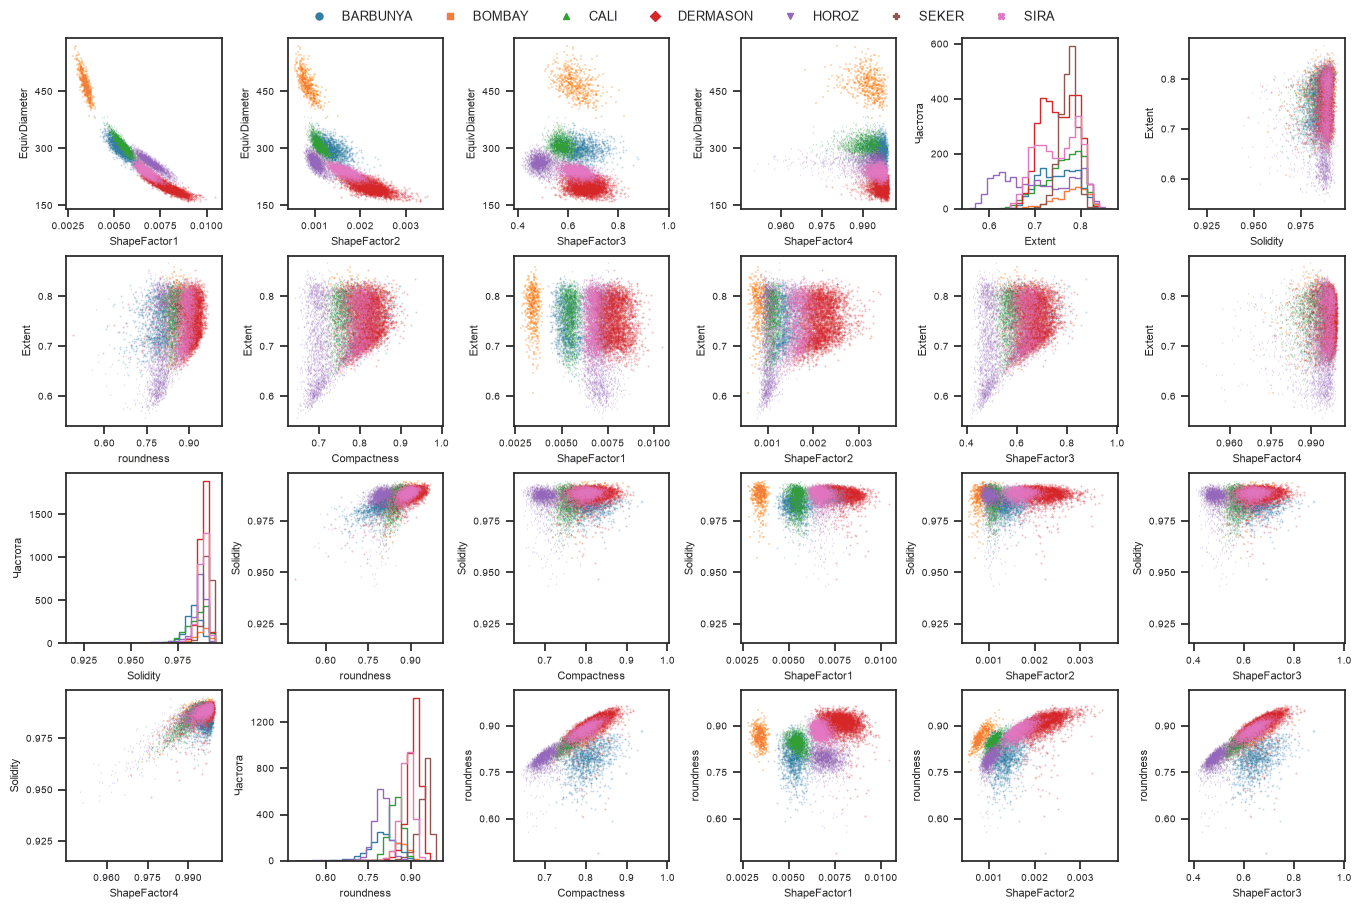

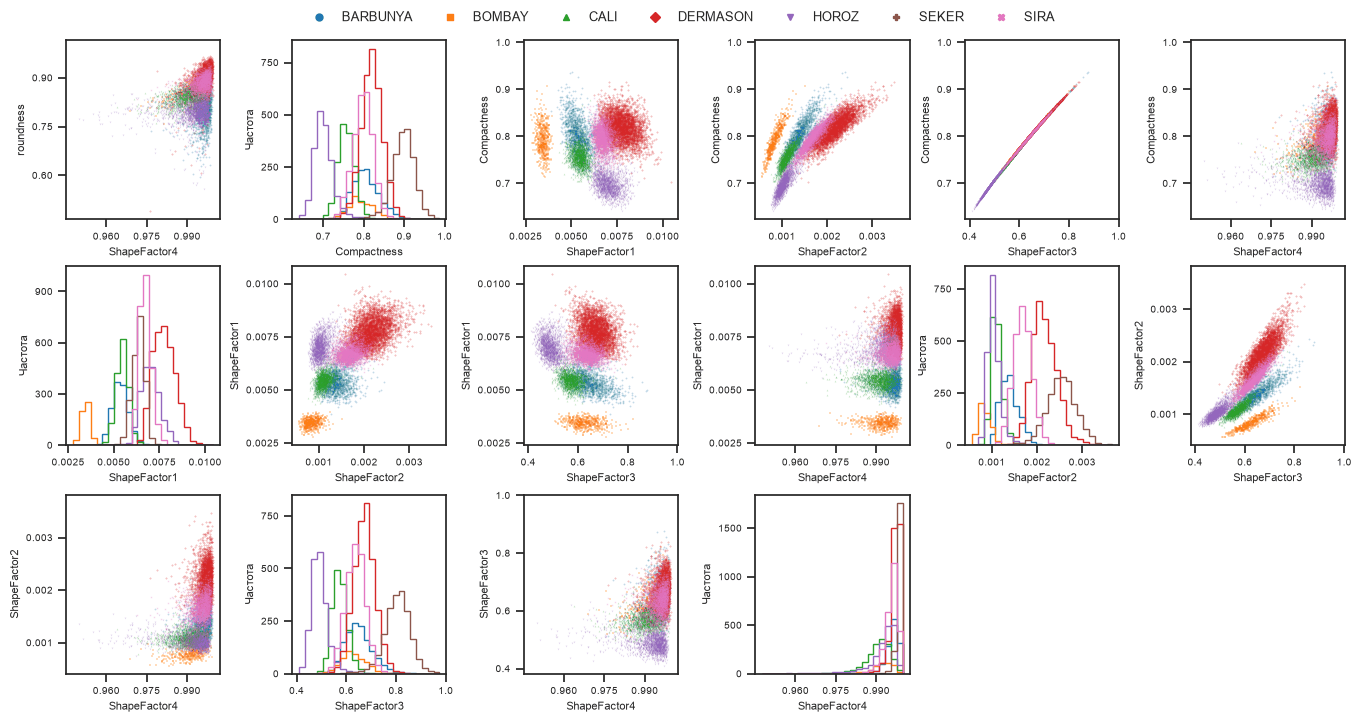

In [7]:
kaggle_api = "https://www.kaggle.com/api/v1/datasets/download/chetalipushkarna/dry-bean-dataset"
with urlopen(kaggle_api, timeout=45) as response:
    contents = response.read()
with ZipFile(BytesIO(contents)) as archive, archive.open("Dry_Bean_Dataset.csv") as csv:
    raw = pd.read_csv(csv).rename(columns={"Class": "class"})
bean_features = raw.columns.drop("class").tolist()
beans = inspect_data(raw, bean_features)
bean_y, bean_classes = pd.factorize(beans["class"], sort=True)
assert len(beans) >= 10_000 and len(bean_features) >= 10 and len(bean_classes) >= 2

from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

def all_bean_pairs(data, features, labels, classes):
    palette = plt.cm.tab10(np.arange(len(classes)))
    markers = ["o", "s", "^", "D", "v", "P", "X"]
    groups = [(data.loc[labels == i], color, marker)
              for i, (color, marker) in enumerate(zip(palette, markers))]
    handles = [Line2D([], [], marker=marker, markersize=5, linestyle="none",
                      color=color, label=name)
               for name, color, marker in zip(classes, palette, markers)]
    pairs = list(itertools.combinations_with_replacement(features, 2))
    for start in range(0, len(pairs), 24):
        panel = pairs[start:start + 24]
        fig, axes = plt.subplots(4, 6, figsize=(13.5, 9), layout="constrained")
        for ax, (ylabel, xlabel) in zip(axes.flat, panel):
            if xlabel == ylabel:
                bins = np.histogram_bin_edges(data[xlabel], bins=24)
                for subset, color, _ in groups:
                    ax.hist(subset[xlabel], bins=bins, histtype="step", color=color)
                ax.set_ylabel("Частота", fontsize=8)
            else:
                for subset, color, marker in groups:
                    ax.scatter(subset[xlabel], subset[ylabel], color=color, s=1.7,
                               marker=marker, alpha=.27, linewidths=0)
                ax.set_ylabel(ylabel, fontsize=8)
            ax.set_xlabel(xlabel, fontsize=8)
            ax.xaxis.set_major_locator(MaxNLocator(4))
            ax.yaxis.set_major_locator(MaxNLocator(4))
            ax.tick_params(labelsize=7)
        for ax in list(axes.flat)[len(panel):]:
            ax.set_visible(False)
        fig.legend(handles=handles, loc="outside upper center", ncol=7, frameon=False, fontsize=9)
        plt.show()

all_bean_pairs(beans, bean_features, bean_y, bean_classes)


## Число компонент для регрессии

Правило Кайзера оставляет компоненты с λ > 1. Для метода ломаной трости
сравниваем долю дисперсии каждой компоненты с ожидаемой долей случайного
разбиения. Оставляем только начальную непрерывную последовательность,
в которой наблюдаемая доля больше ожидаемой. Оба правила используют только
признаки. Для конкретной регрессии разумность выбранного числа компонент
проверяется по её вневыборочной ошибке.

,метод,оставить компонент
0,Кайзер,3
1,Ломаная трость,2


,PC,λ,доля дисперсии,ломаная трость
0,1,8.8746,0.5547,0.2113
1,2,4.2290,0.2643,0.1488
2,3,1.2811,0.0801,0.1175
3,4,0.8183,0.0511,0.0967
4,5,0.4383,0.0274,0.0811
5,6,0.1840,0.0115,0.0686
6,7,0.1116,0.0070,0.0582
7,8,0.0520,0.0033,0.0492
8,9,0.0083,0.0005,0.0414
9,10,0.0015,0.0001,0.0345


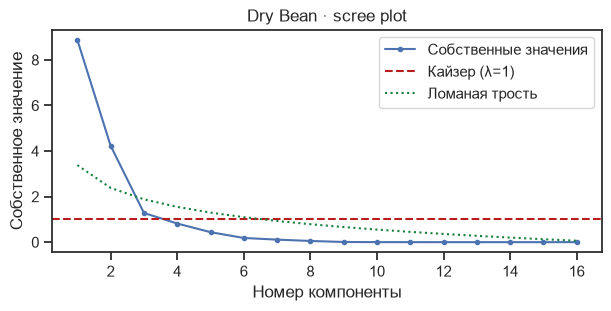

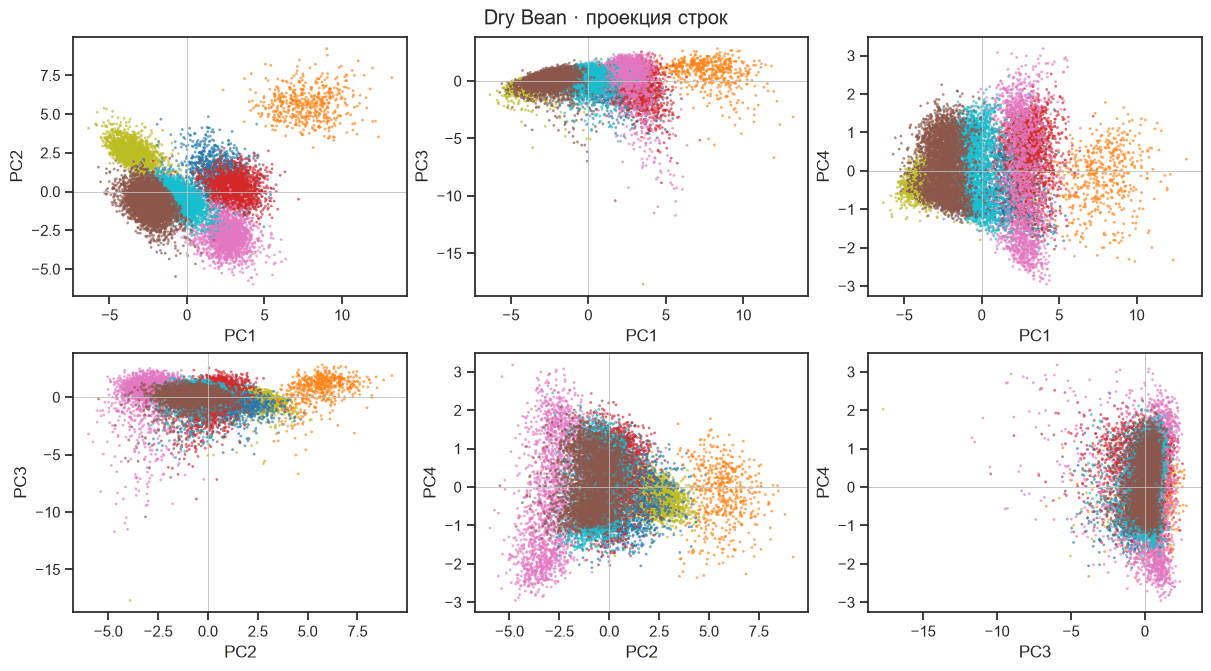

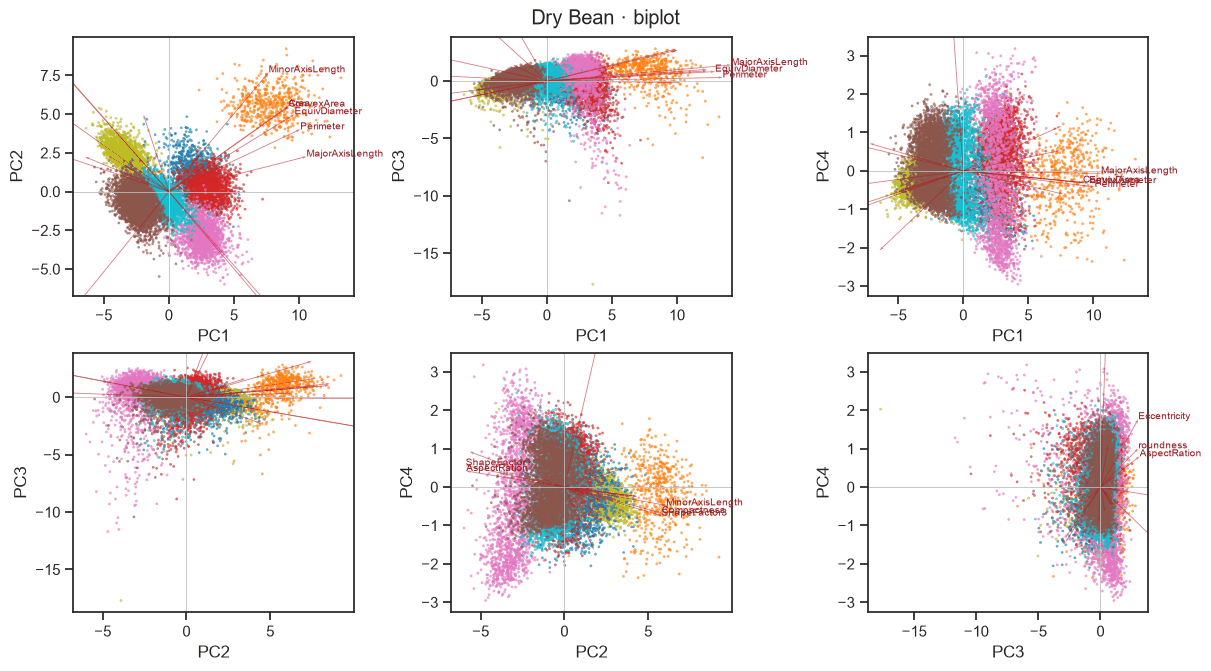

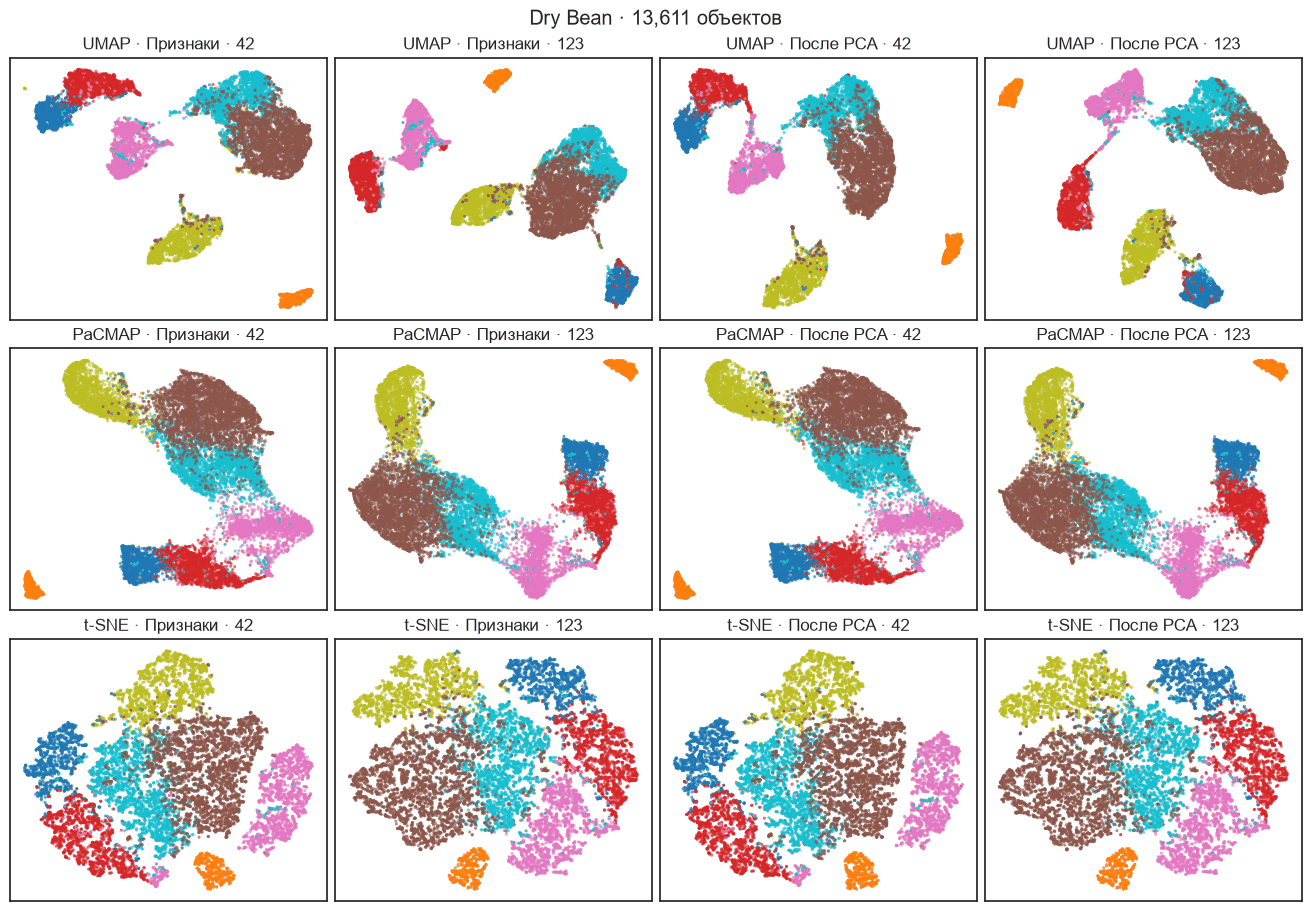

In [8]:
bean_X = beans[bean_features].to_numpy()
bean_model, bean_scores, bean_loadings = correlation_pca(bean_X)
p = len(bean_features)
expected = np.cumsum(1 / np.arange(p, 0, -1))[::-1] / p
above_broken_stick = bean_model.explained_variance_ratio_ > expected
kaiser = np.count_nonzero(bean_model.explained_variance_ > 1)
broken_stick = int(np.cumprod(above_broken_stick).sum())
display(pd.DataFrame(
    {"метод": ["Кайзер", "Ломаная трость"], "оставить компонент": [kaiser, broken_stick]},
))
display(pd.DataFrame({
    "PC": np.arange(1, p + 1),
    "λ": bean_model.explained_variance_,
    "доля дисперсии": bean_model.explained_variance_ratio_,
    "ломаная трость": expected,
}).round(4))
scree(bean_model, "Dry Bean · scree plot", broken_stick=expected)
for arrows in (False, True):
    pc_panels(bean_scores, bean_loadings, bean_features, range(4), "Dry Bean",
              arrows=arrows, colors=bean_y)
embeddings(bean_X, bean_scores, "Dry Bean", colors=bean_y)

В пространстве df_256v линейное преобразование с двумя компонентами сохраняет
всю геометрию стандартизированных признаков, поэтому само по себе оно не упрощает
отделение нулевых ячеек от единичных. Для Dry Bean предварительный PCA сохраняет
10 из 16 компонент и удаляет хвост спектра, поэтому соседства после PCA могут
изменяться. Нелинейные проекции показывают соседства качественно: расстояния
между разными областями и ориентация осей зависят от алгоритма и старта.

Для Dry Bean правило Кайзера оставляет три компоненты, а метод ломаной трости — две. Первые четыре компоненты объясняют 95,0% дисперсии стандартизированных признаков.